# 1. Projektin tavoite: CNN

Projektin tavoiteena on löytää optimaalinen Convolutional Neural Network (CNN) -malli CIFAR-10 aineistosta, joka tunnistaa syötetystä kuvasta onko kuva lentokone, auto, lintu, kissa, peura, koira, sammakko, hevonen, aiva vai kuorma-auto. Tavoitteena on saada testitulosten tarkkuus välille 75-85%. Backendinä käytetään kerasin tensorflowta. Tavoitteena on lopuksi verrata sitä erilliseen dokumenttiin Fully Connected Networkiin (FCN). 

Parhaan mallin löytämiseksi kokeillaan erilaisia suodattimien ja konvoluutiokerrosten määriä sekä regularisointimenetelmiä, kuten Dropoutia ja BatchNormalizationia. Lisäksi tutkitaan data augmentationin vaikutusta mallin tarkkuuteen.

Mallien suorituskykyä vertaillaan testitarkkuuden, loss-arvojen, koulutusajan ja opetettavien parametrien määrän perusteella. Lisäksi tarkastellaan oppimiskäyriä, luokittelutuloksia ja väärin luokiteltuja kuvia.

Lopuksi CNN-mallin tuloksia verrataan erillisessä Jupyter Notebookissa toteutettuun täysin yhdistettyyn neuroverkkoon (Fully Connected Network, FCN). Vertailun tavoitteena on selvittää, miten CNN- ja FCN-arkkitehtuurit eroavat toisistaan kuvantunnistuksessa tarkkuuden ja laskennallisen tehokkuuden näkökulmasta.

# 2. Datan ymmärtäminen

## 2.1 Backend alustus

Alustetaan backend hyödyntämään tehokkainta reittiä mallin kehittämiseen

In [1]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import platform
import pandas as pd

os.environ["KERAS_BACKEND"] = "tensorflow"

import tensorflow as tf
import keras

# Apple Silicon Macilla TensorFlow käyttää CPU:ta nopeempaa ja tarkempaa mallia varten
if platform.system() == "Darwin" and platform.machine() == "arm64":
    tf.config.set_visible_devices([], "GPU")

print("Keras:", keras.__version__)
print("Backend:", keras.backend.backend())
print("TensorFlow:", tf.__version__)
print("CPU:", tf.config.list_physical_devices("CPU"))
print("GPU:", tf.config.list_physical_devices("GPU"))

2026-10-28 14:28:42.661836: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Keras: 3.15.1
Backend: tensorflow
TensorFlow: 2.20.0-dev0+selfbuilt
CPU: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2.2 Datan haku ja tulkinta

Haetaan data kerasin avulla ja tarkistellaan sen kokoa ja tyyppejä

In [3]:
import keras
from keras import layers
import numpy as np

# Datan haku ja tulkinta
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
print(f"x_train: {x_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"x_test: {x_test.shape}")
print(f"y_test: {y_test.shape}")
print(f"Minimi: {x_train.min()}")
print(f"Maksimi: {x_train.max()}")
print(f"Tietotyyppi: {x_train.dtype}")
print(f"Luokat: {np.unique(y_train)}")

# Tyhjät arvot
print("\nTarkistetaan tyhjät arvot:\n")
print("\nTreenidata:\n")
print(f"Treeni kuvien tyhjien arvojen summa: {np.isnan(x_train).sum()}")
print(f"Treeni kuvien kohteiden tyhjien arvojen summa: {np.isnan(y_train).sum()}")
print("\nTestidata\n")
print(f"Testi kuvien tyhjien arvojen summa: {np.isnan(x_test).sum()}")
print(f"Testi kuvien kohteiden tyhjien arvojen summa: {np.isnan(y_test).sum()}")

x_train: (50000, 32, 32, 3)
y_train: (50000, 1)
x_test: (10000, 32, 32, 3)
y_test: (10000, 1)
Minimi: 0
Maksimi: 255
Tietotyyppi: uint8
Luokat: [0 1 2 3 4 5 6 7 8 9]

Tarkistetaan tyhjät arvot:


Treenidata:

Treeni kuvien tyhjien arvojen summa: 0
Treeni kuvien kohteiden tyhjien arvojen summa: 0

Testidata

Testi kuvien tyhjien arvojen summa: 0
Testi kuvien kohteiden tyhjien arvojen summa: 0


## 2.3 Datan tulkinta
CIFAR-10 antaa 60000 kuvaa, joista 50000 menee koulutukseen ja 10000 testaamiseen. Kuvat on koossa 32 x 32 ja 3 värikanavaa. Värit on 0-255 eli 8 bittisiä. Kuvat on jaettu 10 eri luokkaan: 0 = lentokone, 1 = auto, 2 = lintu, 3 = kissa, 4 = peura, 5 = koira, 6 = sammakko, 7 = hevonen, 8 = laiva ja 9 = kuorma-auto [lähde dokumentaatio](https://keras.io/api/datasets/cifar10/?utm_source=chatgpt.com).

Tyhjiä arvoja ei ole datassa.

In [4]:
# Ensimmäiset 10 luokkatunnusta
print("Datan ensimmäisen kymmenen rivin luokkatunnukset:\n")
print(y_train[:10])

# Ensimmäisen kuvan kaikki pikseliarvot
print("\nEnsimmäisen kuvan kaikki pikseliarvot:\n")
print(x_train[0])

# Ensimmäisen kuvan koko ja muoto
print("\nEnsimmäisen kuvan koko 32 x 32 =\n")
print(x_train[0].size)
print("\nEnsimmäisen kuvan muoto\n")
print(x_train[0].shape)

# Ensimmäisen pikselin RGB-arvot
print("\nEsimmäisen pikselin RGB arvot:\n")
print(x_train[0, 0, 0])

Datan ensimmäisen kymmenen rivin luokkatunnukset:

[[6]
 [9]
 [9]
 [4]
 [1]
 [1]
 [2]
 [7]
 [8]
 [3]]

Ensimmäisen kuvan kaikki pikseliarvot:

[[[ 59  62  63]
  [ 43  46  45]
  [ 50  48  43]
  ...
  [158 132 108]
  [152 125 102]
  [148 124 103]]

 [[ 16  20  20]
  [  0   0   0]
  [ 18   8   0]
  ...
  [123  88  55]
  [119  83  50]
  [122  87  57]]

 [[ 25  24  21]
  [ 16   7   0]
  [ 49  27   8]
  ...
  [118  84  50]
  [120  84  50]
  [109  73  42]]

 ...

 [[208 170  96]
  [201 153  34]
  [198 161  26]
  ...
  [160 133  70]
  [ 56  31   7]
  [ 53  34  20]]

 [[180 139  96]
  [173 123  42]
  [186 144  30]
  ...
  [184 148  94]
  [ 97  62  34]
  [ 83  53  34]]

 [[177 144 116]
  [168 129  94]
  [179 142  87]
  ...
  [216 184 140]
  [151 118  84]
  [123  92  72]]]

Ensimmäisen kuvan koko 32 x 32 =

3072

Ensimmäisen kuvan muoto

(32, 32, 3)

Esimmäisen pikselin RGB arvot:

[59 62 63]


## 2.4 Kuvien ja datan tulkinta

Kuvat ovat jo oikeassa muodossa (32 x 32 x 3), värikuvia (pikselit välillä 0-255) ja 3 kanavisia. Tyhjiä arvoja ei ole.

# 3. Datan valmistelu

## 3.1 Nimetään luokat

Määritetään luokkien nimet visualisoinnin helpottamiseski:

In [5]:
# Määritetään luokkien nimet
class_names = [
    "lentokone",
    "auto",
    "lintu",
    "kissa",
    "peura",
    "koira",
    "sammakko",
    "hevonen",
    "laiva",
    "kuorma-auto"
]

## 3.2 Normalisoidaan pikselit

Alustetaan pikselit arvojen 0-1 välille jakamalla koolla 255. Näin neuroverkko oppii paremmin datan piirteet, kun syötearvot ovat pienellä ja yhtenäisellä asteikolla.

In [6]:
# Normalisoidaan pikseliarvot välille 0–1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [7]:
# Datan tarkistus
print(f"Treeni kuvien muoto {x_train.shape}")
print(f"Treeni kuvien luokkien muoto {y_train.shape}")

print(f"Testi kuvien muoto {x_test.shape}")
print(f"Testi kuvien luokkien muoto {y_test.shape}")

# Tarkistetaan normalisoinnin onnistuminen
print(f"Minimi treenidatassa: {x_train.min()}")
print(f"Maksimi treenidatassa: {x_train.max()}")
print(f"Kesiarvo treenidatassa: {x_train.mean()}")

print(f"Minimi testidatassa: {x_test.min()}")
print(f"Maksimi testidatassa: {x_test.max()}")
print(f"Kesiarvo testidatassa: {x_test.mean()}")

Treeni kuvien muoto (50000, 32, 32, 3)
Treeni kuvien luokkien muoto (50000, 1)
Testi kuvien muoto (10000, 32, 32, 3)
Testi kuvien luokkien muoto (10000, 1)
Minimi treenidatassa: 0.0
Maksimi treenidatassa: 1.0
Kesiarvo treenidatassa: 0.4733630120754242
Minimi testidatassa: 0.0
Maksimi testidatassa: 1.0
Kesiarvo testidatassa: 0.4765849709510803


## 3.3 Datan valmistelun johtopäätökset
Pikselit normalisoitiin 0-1 välille ja muoto säilyi ennallaan

## 3.4 RGB-standardointi

Standardoidaan RBG-kanavat ja vertaillaan sen vaikutusta parhaimpiin todettuihin malleihin. Luodaan omat validointi data ja 

In [8]:
# Validointikuvien määrä (10 %)
val_size = int(len(x_train) * 0.1)

# Lasketaan RGB-kanavien tilastot vain koulutusosasta
rgb_mean = x_train[:-val_size].mean(
    axis=(0, 1, 2), keepdims=True
)

rgb_std = x_train[:-val_size].std(
    axis=(0, 1, 2), keepdims=True
)

# Luodaan standardoitu versio koko harjoitusaineistosta
# (myös validointikuvat käyttäen koulutusosan tilastoja)
x_train_std = (x_train - rgb_mean) / rgb_std

print("RGB-keskiarvot:", rgb_mean.flatten())
print("RGB-keskihajonnat:", rgb_std.flatten())
print("Standardoidun datan muoto:", x_train_std.shape)


RGB-keskiarvot: [0.4915495  0.48212427 0.44642738]
RGB-keskihajonnat: [0.24715227 0.24367483 0.26173463]
Standardoidun datan muoto: (50000, 32, 32, 3)


# 4. Mallinnus

Luodaan erilaisia malleja saadakseen mahdollisimman tehokas ja tarkka ennustamiseen uuden kuvan mukaan luokittelemaan oikein.

Luodaan ajastusfunktio (AI-generoitu) tallentaakseen ajat selkeästi historiaan.

Lisäksi määritetään yleinen pysäytin.

In [9]:
# AI:lla generoitu timeri saadakseen ajat selkeämmin ajat näkyviin aikavertailuun
import time

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.perf_counter() - self.start_time
        self.epoch_times.append(elapsed)

In [10]:
# Erilliset timerit, jotta arvot pysyvät vertailukelpoisina
timer_32_64_2layer = EpochTimer()
timer_64_128_2layer = EpochTimer()
timer_16_32_2layer = EpochTimer()
timer_32_32_64_3layer = EpochTimer()
timer_32_32_64_64_4layer = EpochTimer()
timer_64_64_128_3layer = EpochTimer()

## 4.1 Pysäyttimen määritys

Määritetään stop arvo jotta ei tarvitse kaikkia kierroksia (epochs) käydä, vaan pysäytetään kun malli alkaa ylioppia. Seurataan 3 peräkkäistä validaatio menetyksen (validation loss) -arvoa.

In [11]:
# Määritetään yleinen pysäytin
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                     restore_best_weights=True)

### 4.2 CNN-malli: 32 ja 64 suodatinta
Kokeillaan miten malli kehittyy kaksikerroksisella mallilla, jossa ensimmäinen kerros käyttää 32 suodattinta, antaen 32 piirrekarttaa ja toinen kerrot 64 suodatinta ja 64 eri piirrekarttaa. Kernel koolla 3 ja sisennys arvolla "same". Aktivointi on ReLU ja askelpituutena (stride) oletusarvo 1.

#### 4.2.1 Mallin rakentaminen

In [12]:
keras.utils.set_random_seed(0)
model32_64_2layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 32 suodatinta
    layers.MaxPooling2D(pool_size=2),  # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 32
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 64
    layers.Flatten(),
    layers.Dense(10, activation="softmax")  # valitaan 10 luokan takia
])

I0000 00:00:1793190528.676352     524 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22388 MB memory:  -> device: 0, name: AMD Radeon RX 7900 XTX, pci bus id: 0000:03:00.0


#### 4.2.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan adam, koska se muokkaa painokertoimien päivityksiä koulutuksen aikana ja pyrkii pienentämää loss-arvoa. Kokonaisluku luokituksen vuoksi (0-9) sparse_categorical_crossentropy parametri toimii parhaiten. Arviointi metriikka on tarkkuus (accuracy). Pysäytetään kun validoinnin menetys (validation loss) nousee 3 peräkkäisen arvon jälkeen.

In [13]:
model32_64_2layer.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

#### 4.2.3 Mallin kouluttaminen

In [14]:
# Tallennetaan historia myöhempää tarkastelua varten.
history_32_64_2layer = model32_64_2layer.fit(x_train, y_train, epochs=20, validation_split=0.1, callbacks=[stop, timer_32_64_2layer])

# Tallennetaan ajat historiaan myöhempää tarkastelua varten.
history_32_64_2layer.history["epoch_time_seconds"] = timer_32_64_2layer.epoch_times

Epoch 1/20


2026-10-28 14:28:51.762048: I external/local_xla/xla/service/service.cc:163] XLA service 0x75cb74006bf0 initialized for platform ROCM (this does not guarantee that XLA will be used). Devices:
2026-10-28 14:28:51.762106: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): AMD Radeon RX 7900 XTX, AMDGPU ISA version: gfx1100
2026-10-28 14:28:51.794150: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


  28/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1786 - loss: 2.2562

I0000 00:00:1793190533.319162     632 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1393/1407 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4939 - loss: 1.4278

2026-10-28 14:28:58.477287: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4951 - loss: 1.4253 - val_accuracy: 0.6080 - val_loss: 1.1341
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6258 - loss: 1.0731 - val_accuracy: 0.6540 - val_loss: 1.0041
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6726 - loss: 0.9441 - val_accuracy: 0.6716 - val_loss: 0.9654
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7016 - loss: 0.8602 - val_accuracy: 0.6844 - val_loss: 0.9292
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7276 - loss: 0.7920 - val_accuracy: 0.6954 - val_loss: 0.8991
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7472 - loss: 0.7345 - val_accuracy: 0.7034 - val_loss: 0.8881
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7654 - loss: 0.6841 - val_accuracy: 0.7008 - val_loss: 0.9162
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7812 - loss: 0.6406 - val_accura

#### 4.2.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [15]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_32_64_2layer.history["val_loss"])

results_32_64 = [{
    "Malli": "32/64 (2 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_32_64_2layer.history["loss"][best_idx],
    "Validation loss": history_32_64_2layer.history["val_loss"][best_idx],
    "Training accuracy": history_32_64_2layer.history["accuracy"][best_idx],
    "Validation accuracy": history_32_64_2layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_32_64_2layer.epoch_times)
}]

df_results_32_64 = pd.DataFrame(results_32_64)

display(df_results_32_64.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,32/64 (2 kerrosta),6,0.7345,0.8881,0.7472,0.7034,50.593


#### 4.2.5 Tulosten visualisointi ja analysointi
Taulukoidaan mallin validointi menetys (validation loss) ja menetys (loss), ja mallin suoritusajat

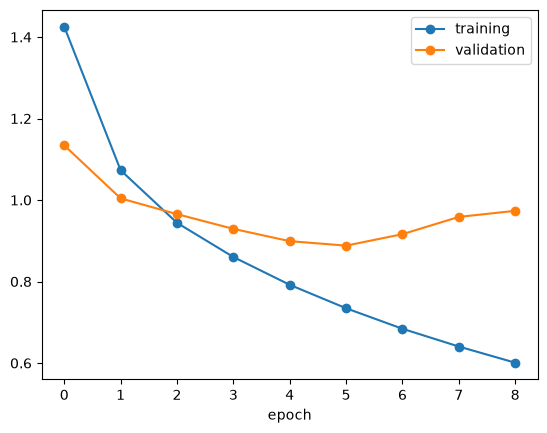

/tmp/ipykernel_524/1773337734.py:13: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  df_times_32_64_2layer.loc[len(df_times_32_64_2layer)] = ["Keski suoritusaika", sum(timer_32_64_2layer.epoch_times[:-3]) / len(timer_32_64_2layer.epoch_times[:-3])]


Epoch,Aika (s)
1,10.49
2,4.97
3,5.08
4,5.04
5,5.06
6,4.98
Keski suoritusaika,5.94
Kokonaissuoritusaika,50.59


In [16]:
import matplotlib.pyplot as plt

plt.plot(history_32_64_2layer.history["loss"], marker="o", label="training")
plt.plot(history_32_64_2layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_32_64_2layer = pd.DataFrame({"Epoch": range(1, len(timer_32_64_2layer.epoch_times[:-3]) + 1), "Aika (s)": timer_32_64_2layer.epoch_times[:-3]})

# Keskimääräinen suoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_32_64_2layer.loc[len(df_times_32_64_2layer)] = ["Keski suoritusaika", sum(timer_32_64_2layer.epoch_times[:-3]) / len(timer_32_64_2layer.epoch_times[:-3])]

# Kokonaissuoritusaika koulutukselle.
df_times_32_64_2layer.loc[len(df_times_32_64_2layer)] = ["Kokonaissuoritusaika", sum(timer_32_64_2layer.epoch_times)]

# Pyöristetään ajat 2 tarkkuudella ja näytetään aikojen dataframe. Poistetaan turha indeksi visualisoinnin selkeyttämiseksi.
display(df_times_32_64_2layer.style.hide(axis="index").format({"Aika (s)": "{:.2f}"}))

#### 4.2.6 Johtopäätökset

Pysähdys tapahtui 9 epochin jälkeen, se ja kuvaaja indikoi epochille arvoa 6. Malli suoriutui validointi tarkkuudella 70,34% parhaan validation lossin kohdalla ja testitarkkuudella 69,12%. Malli toimii suhteellisen hyvin, mutta optimoitavaa vielä löytyy.

### 4.3 CNN-malli: 64 ja 128 suodatinta
Kokeillaan miten malli kehittyy kaksikerroksisella mallilla, jossa ensimmäinen kerros käyttää 64 suodattinta, antaen 64 piirrekarttaa ja toinen kerrot 128 suodatinta ja 128 eri piirrekarttaa. Kernel koolla 3 ja sisennys arvolla "same". Aktivointi on ReLU ja askelpituutena (stride) oletusarvo 1.

#### 4.3.1 Mallin rakentaminen

In [17]:
keras.utils.set_random_seed(0)
model64_128_2layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2),  # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 64
    layers.Conv2D(128, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 128 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 128
    layers.Flatten(),
    layers.Dense(10, activation="softmax")  # valitaan 10 luokan takia
])

#### 4.3.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan adam, koska se muokkaa painokertoimien päivityksiä koulutuksen aikana ja pyrkii pienentämää loss-arvoa. Kokonaisluku luokituksen vuoksi (0-9) sparse_categorical_crossentropy parametri toimii parhaiten. Arviointi metriikka on tarkkuus (accuracy). Pysäytetään samaan tapaan kuin muissa.

In [18]:
model64_128_2layer.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

#### 4.3.3 Mallin kouluttaminen

In [19]:
# Tallennetaan historia myöhempää tarkastelua varten.
history_64_128_2layer = model64_128_2layer.fit(x_train, y_train, epochs=20, validation_split=0.1, callbacks=[stop, timer_64_128_2layer])

# Tallennetaan ajat historiaan myöhempää tarkastelua varten.
history_64_128_2layer.history["epoch_time_seconds"] = timer_64_128_2layer.epoch_times

Epoch 1/20
1404/1407 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5183 - loss: 1.3603

2026-10-28 14:29:49.462724: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.5185 - loss: 1.3598 - val_accuracy: 0.6320 - val_loss: 1.0585
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6552 - loss: 0.9917 - val_accuracy: 0.6802 - val_loss: 0.9439
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7091 - loss: 0.8487 - val_accuracy: 0.6922 - val_loss: 0.9242
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7444 - loss: 0.7484 - val_accuracy: 0.7072 - val_loss: 0.8982
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7743 - loss: 0.6641 - val_accuracy: 0.7180 - val_loss: 0.8685
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7990 - loss: 0.5967 - val_accuracy: 0.7152 - val_loss: 0.8866
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8188 - loss: 0.5373 - val_accuracy: 0.7154 - val_loss: 0.9335
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8368 - loss: 0.4799 - val_accura

#### 4.3.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [20]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_64_128_2layer.history["val_loss"])

results_64_128 = [{
    "Malli": "64/128 (2 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_64_128_2layer.history["loss"][best_idx],
    "Validation loss": history_64_128_2layer.history["val_loss"][best_idx],
    "Training accuracy": history_64_128_2layer.history["accuracy"][best_idx],
    "Validation accuracy": history_64_128_2layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_64_128_2layer.epoch_times)
}]

df_results_64_128 = pd.DataFrame(results_64_128)

display(df_results_64_128.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,64/128 (2 kerrosta),5,0.6641,0.8685,0.7743,0.718,45.3581


#### 4.3.5 Tulosten visualisointi ja analysointi
Taulukoidaan mallin validointi menetys (validation loss) ja menetys (loss), ja mallin suoritusajat

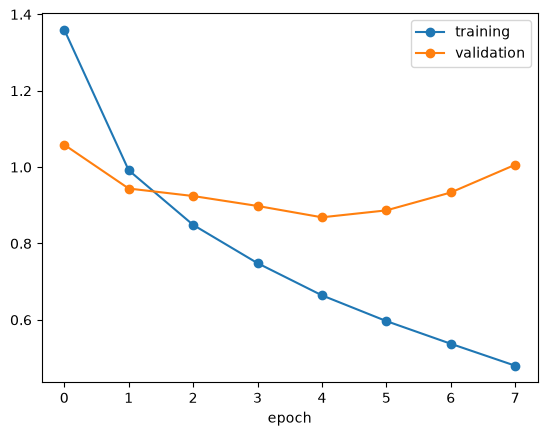

/tmp/ipykernel_524/2250967330.py:11: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  df_times_64_128_2layer.loc[len(df_times_64_128_2layer)] = ["Keski suoritusaika", sum(timer_64_128_2layer.epoch_times[:-3]) / len(timer_64_128_2layer.epoch_times[:-3])]


Epoch,Aika (s)
1,9.75
2,5.21
3,5.23
4,5.21
5,5.07
Keski suoritusaika,6.09
Kokonaissuoritusaika,45.36


In [21]:
plt.plot(history_64_128_2layer.history["loss"], marker="o", label="training")
plt.plot(history_64_128_2layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_64_128_2layer = pd.DataFrame({"Epoch": range(1, len(timer_64_128_2layer.epoch_times[:-3]) + 1), "Aika (s)": timer_64_128_2layer.epoch_times[:-3]})

# Keskimääräinen suoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_64_128_2layer.loc[len(df_times_64_128_2layer)] = ["Keski suoritusaika", sum(timer_64_128_2layer.epoch_times[:-3]) / len(timer_64_128_2layer.epoch_times[:-3])]

# Kokonaissuoritusaika koulutukselle.
df_times_64_128_2layer.loc[len(df_times_64_128_2layer)] = ["Kokonaissuoritusaika", sum(timer_64_128_2layer.epoch_times)]

# Pyöristetään ajat 2 tarkkuudella ja näytetään aikojen dataframe. Poistetaan turha indeksi visualisoinnin selkeyttämiseksi.
display(df_times_64_128_2layer.style.hide(axis="index").format({"Aika (s)": "{:.2f}"}))

#### 4.3.6 Johtopäätökset

Aika nousi 64/32 malliin verrattuna lähes kolminkertaistuu. Tarkkuudet parani validaatiolla 71,80% ja testillä 69,80%. Konvulointi piirteiden nosto paransi hieman mallin suorituskykyä, mutta koulutusaika lyheni hieman.

### 4.4 CNN-malli: 16 ja 32 suodatinta

Kokeillaan miten pienempi suodatinmäärä vaikuttaa mallin tarkkuuteen ja suoritusaikaan. Ensimmäinen konvoluutiokerros käyttää 16 suodatinta ja toinen 32 suodatinta. Kernel koko on 3 ja padding-arvo "same". Aktivointina toimii ReLU ja askelpituutena (stride) oletusarvo 1.

#### 4.4.1 Mallin rakentaminen

In [22]:
keras.utils.set_random_seed(0)
model16_32_2layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 16 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 16
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 32 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 32
    layers.Flatten(),
    layers.Dense(10, activation="softmax") # Valitaan 10 luokan takia
])

#### 4.4.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan Adam, joka päivittää mallin painokertoimia koulutuksen aikana pyrkien pienentämään loss-arvoa. Kokonaislukuluokituksen (0–9) vuoksi käytetään sparse_categorical_crossentropy-menetysfunktiota. Arviointimittarina toimii tarkkuus (accuracy). Koulutuksessa käytetään samaa EarlyStopping-menetelmää kuin muissa malleissa.

In [23]:
model16_32_2layer.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [24]:
#### 4.4.3 Mallin kouluttaminen

In [25]:
# Tallennetaan historia myöhempää tarkastelua varten
history_16_32_2layer = model16_32_2layer.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[stop, timer_16_32_2layer]
)

# Tallennetaan ajat historiaan myöhempää tarkastelua varten
history_16_32_2layer.history["epoch_time_seconds"] = timer_16_32_2layer.epoch_times

Epoch 1/20
1403/1407 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4517 - loss: 1.5416

2026-10-28 14:30:35.579916: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.4520 - loss: 1.5411 - val_accuracy: 0.5676 - val_loss: 1.2537
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5811 - loss: 1.2052 - val_accuracy: 0.6154 - val_loss: 1.1202
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6277 - loss: 1.0750 - val_accuracy: 0.6450 - val_loss: 1.0445
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6576 - loss: 0.9926 - val_accuracy: 0.6596 - val_loss: 1.0006
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6755 - loss: 0.9377 - val_accuracy: 0.6688 - val_loss: 0.9694
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6894 - loss: 0.8946 - val_accuracy: 0.6744 - val_loss: 0.9522
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7021 - loss: 0.8593 - val_accuracy: 0.6754 - val_loss: 0.9493
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7138 - loss: 0.8284 - val_accurac

#### 4.4.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [26]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_16_32_2layer.history["val_loss"])

results_16_32 = [{
    "Malli": "16/32 (2 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_16_32_2layer.history["loss"][best_idx],
    "Validation loss": history_16_32_2layer.history["val_loss"][best_idx],
    "Training accuracy": history_16_32_2layer.history["accuracy"][best_idx],
    "Validation accuracy": history_16_32_2layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_16_32_2layer.epoch_times)
}]

df_results_16_32 = pd.DataFrame(results_16_32)

display(df_results_16_32.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,16/32 (2 kerrosta),12,0.7416,0.9256,0.7468,0.6862,78.0981


#### 4.4.5 Tulosten visualisointi ja analysointi

Visualisoidaan mallin harjoitusdatan menetys (loss) ja validointidatan menetys (validation loss). Lisäksi taulukoidaan epochien suoritusajat, keskimääräinen suoritusaika ja koulutuksen kokonaisaika.

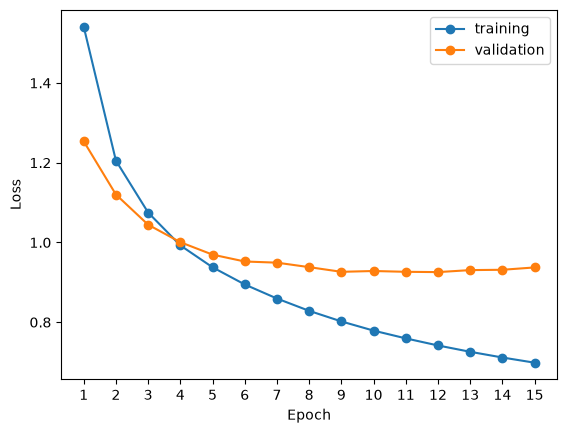

/tmp/ipykernel_524/3519414046.py:18: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  df_times_16_32_2layer.loc[len(df_times_16_32_2layer)] = [


Epoch,Aika (s)
1,9.25
2,4.95
3,4.89
4,4.88
5,4.90
6,4.89
7,4.87
8,4.86
9,4.92
10,5.14


In [27]:
epochs = range(1, len(history_16_32_2layer.history["loss"]) + 1)

plt.plot(epochs, history_16_32_2layer.history["loss"], marker="o", label="training")
plt.plot(epochs, history_16_32_2layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen
df_times_16_32_2layer = pd.DataFrame({
    "Epoch": range(1, len(timer_16_32_2layer.epoch_times) + 1),
    "Aika (s)": timer_16_32_2layer.epoch_times
})

# Keskimääräinen suoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_16_32_2layer.loc[len(df_times_16_32_2layer)] = [
    "Keski suoritusaika",
    sum(timer_16_32_2layer.epoch_times[:-3]) / len(timer_16_32_2layer.epoch_times[:-3])
]

# Kokonaissuoritusaika
df_times_16_32_2layer.loc[len(df_times_16_32_2layer)] = [
    "Kokonaissuoritusaika",
    sum(timer_16_32_2layer.epoch_times)
]

# Näytetään dataframe ilman indeksejä
display(
    df_times_16_32_2layer.style
    .hide(axis="index")
    .format({"Aika (s)": "{:.2f}"})
)

#### 4.4.6 Johtopäätökset

16/32-malli saavutti testitarkkuuden 68,00 % ja validointitarkkuuden 68,62 %. Paras validation loss (0,9256) saavutettiin epochilla 12 ja koulutus pysähtyi 15 epochin jälkeen.

32/64-malli saavutti testitarkkuuden 69,60 % ja validointitarkkuuden 70,80 %. Paras validation loss (0,8798) saavutettiin epochilla 6. Koulutuksen kokonaisaika oli noin 80 sekuntia ja parametreja oli 60 362. Verrattuna 16/32-malliin testitarkkuus parani **1,60 prosenttiyksikköä** ja validointitarkkuus **1,82 prosenttiyksikköä**. Koulutusaika oli myös noin 14 % lyhyempi, vaikka parametrimäärä oli yli kaksinkertainen. Aika paranee selkeästi, kun kierrosmäärä laskee 14:sta 8:an.

64/128-malli saavutti aiemmassa testiarvioinnissa testitarkkuuden 69,80 % ja koulutuksessa validointitarkkuuden 71,48 %. Paras validation loss (0,8940) saavutettiin epochilla 6. Koulutuksen kokonaisaika oli noin kolmin kertainen verrattuna kevyempään 32/64-malliin. Verrattuna 32/64-malliin testitarkkuus oli **0,58 prosenttiyksikköä** ja validointitarkkuus **0,68 prosenttiyksikköä** parempi. Lisäksi validation loss oli hieman suurempi kuin 32/64-mallilla.

#### 4.4.7 Loppuyhteenveto

32/64-malli osoittautui näistä kolmesta parhaaksi vaihtoehdoksi tarkkuuden ja koulutusajan suhteen. Pienempi 16/32-malli oli parametrimäärältään kevyempi, mutta sen testitarkkuus jäi **1,60 prosenttiyksikköä** ja validointitarkkuus **1,82 prosenttiyksikköä** heikommaksi. Myöskään kokonaiskoulutusaika ei lyhentynyt.

Suurempi 64/128-malli saavutti parhaat tarkkuudet, mutta parannukset jäivät alle yhden prosenttiyksikön suhteessa 32/64-malliin. Samalla koulutusaika lähes kolminkertaistui ja parametrimäärä kasvoi merkittävästi.

Tulosten perusteella **32/64-malli valitaan kaksikerroksisten CNN-mallien parhaaksi vaihtoehdoksi** jatkovertailua varten, sillä sen tarkkuus oli lähellä suuremman mallin tuloksia huomattavasti pienemmällä laskentakustannuksella.

### 4.5 CNN-malli: 32 ja 64 suodatinta: kolmas ja neljäs kerros.
Kokeillaan miten malli kehittyy kerroksia kasvattaessa kahdesta kolmeen. Pidetään samat määritteet, eli ensimmäinen kerros käyttää 32 suodattinta, antaen 32 piirrekarttaa. Lisätään toinen Conv2D(32) kerros väliin ja kolmas kerros sama 64 suodatinta ja 64 eri piirrekarttaa. Kernel koolla 3 ja sisennys arvolla "same". Aktivointi on ReLU ja askelpituutena (stride) oletusarvo 1.

#### 4.5.1 Mallin rakentaminen: 3 kerrosta 32/32/64

In [28]:
keras.utils.set_random_seed(0)
model32_32_64_3layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 32 suodatinta
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 32 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 32
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Kolmas kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 64
    layers.Flatten(),
    layers.Dense(10, activation="softmax") # Valitaan 10 luokan takia
])

#### 4.5.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan Adam, joka päivittää mallin painokertoimia koulutuksen aikana pyrkien pienentämään loss-arvoa. Kokonaislukuluokituksen (0–9) vuoksi käytetään sparse_categorical_crossentropy-menetysfunktiota. Arviointimittarina toimii tarkkuus (accuracy). Koulutuksessa käytetään samaa EarlyStopping-menetelmää kuin muissa malleissa.

In [29]:
model32_32_64_3layer.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#### 4.5.3 Mallin kouluttaminen

In [30]:
# Tallennetaan historia myöhempää tarkastelua varten
history_32_32_64_3layer = model32_32_64_3layer.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[stop, timer_32_32_64_3layer]
)

# Tallennetaan ajat historiaan myöhempää tarkastelua varten
history_32_32_64_3layer.history["epoch_time_seconds"] = timer_32_32_64_3layer.epoch_times

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.5057 - loss: 1.3892 - val_accuracy: 0.6430 - val_loss: 1.0308
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6621 - loss: 0.9736 - val_accuracy: 0.6968 - val_loss: 0.8890
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7153 - loss: 0.8264 - val_accuracy: 0.7124 - val_loss: 0.8371
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7515 - loss: 0.7297 - val_accuracy: 0.7258 - val_loss: 0.8225
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7753 - loss: 0.6556 - val_accuracy: 0.7242 - val_loss: 0.8390
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7972 - loss: 0.5940 - val_accuracy: 0.7224 - val_loss: 0.8750
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8160 - loss: 0.5426 - val_accuracy: 0.7174 - val_loss: 0.9020


#### 4.5.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [31]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_32_32_64_3layer.history["val_loss"])

results_32_32_64 = [{
    "Malli": "32/32/64 (3 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_32_32_64_3layer.history["loss"][best_idx],
    "Validation loss": history_32_32_64_3layer.history["val_loss"][best_idx],
    "Training accuracy": history_32_32_64_3layer.history["accuracy"][best_idx],
    "Validation accuracy": history_32_32_64_3layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_32_32_64_3layer.epoch_times)
}]

df_results_32_32_64 = pd.DataFrame(results_32_32_64)

display(df_results_32_32_64.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,32/32/64 (3 kerrosta),4,0.7297,0.8225,0.7515,0.7258,41.5618


#### 4.5.5 Tulosten visualisointi ja analysointi

Visualisoidaan mallin harjoitusdatan menetys (loss) ja validointidatan menetys (validation loss). Lisäksi taulukoidaan epochien suoritusajat, keskimääräinen suoritusaika ja koulutuksen kokonaisaika.

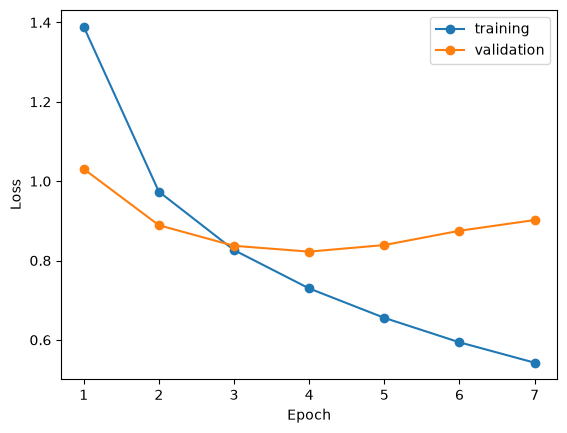

/tmp/ipykernel_524/2800812891.py:18: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  df_times_32_32_64_3layer.loc[len(df_times_32_32_64_3layer)] = [


Epoch,Aika (s)
1,8.38
2,5.53
3,5.49
4,5.52
5,5.52
6,5.55
7,5.57
Keski suoritusaika,6.23
Kokonaissuoritusaika,41.56


In [32]:
epochs = range(1, len(history_32_32_64_3layer.history["loss"]) + 1)

plt.plot(epochs, history_32_32_64_3layer.history["loss"], marker="o", label="training")
plt.plot(epochs, history_32_32_64_3layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen
df_times_32_32_64_3layer = pd.DataFrame({
    "Epoch": range(1, len(timer_32_32_64_3layer.epoch_times) + 1),
    "Aika (s)": timer_32_32_64_3layer.epoch_times
})

# Keskimääräinen suoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_32_32_64_3layer.loc[len(df_times_32_32_64_3layer)] = [
    "Keski suoritusaika",
    sum(timer_32_32_64_3layer.epoch_times[:-3]) / len(timer_32_32_64_3layer.epoch_times[:-3])
]

# Kokonaissuoritusaika
df_times_32_32_64_3layer.loc[len(df_times_32_32_64_3layer)] = [
    "Kokonaissuoritusaika",
    sum(timer_32_32_64_3layer.epoch_times)
]

# Näytetään dataframe ilman indeksejä
display(
    df_times_32_32_64_3layer.style
    .hide(axis="index")
    .format({"Aika (s)": "{:.2f}"})
)

## 4.6.1 Mallin rakentaminen: 32/32/64/64

Kokeillaan tuoko neljäs kerros 64 suodattimella tarkkuutta suhteessa suoritusaikaan.

In [33]:
keras.utils.set_random_seed(0)

model32_32_64_64_4layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 32 suodatinta
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 32 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 32
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Kolmas kerros 64 suodatinta
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Neljäs kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 64
    layers.Flatten(),
    layers.Dense(10, activation="softmax") # 10 neuronia CIFAR-10:n luokkia varten
])

#### 4.6.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan Adam, joka päivittää mallin painokertoimia koulutuksen aikana pyrkien pienentämään loss-arvoa. Kokonaislukuluokituksen (0–9) vuoksi käytetään sparse_categorical_crossentropy-menetysfunktiota. Arviointimittarina toimii tarkkuus (accuracy). Koulutuksessa käytetään samaa EarlyStopping-menetelmää kuin muissa malleissa.

In [34]:
model32_32_64_64_4layer.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#### 4.6.3 Mallin kouluttaminen

In [35]:
# Tallennetaan historia myöhempää tarkastelua varten
history_32_32_64_64_4layer = model32_32_64_64_4layer.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[stop, timer_32_32_64_64_4layer]
)

# Tallennetaan ajat historiaan myöhempää tarkastelua varten
history_32_32_64_64_4layer.history["epoch_time_seconds"] = timer_32_32_64_64_4layer.epoch_times

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.4994 - loss: 1.3898 - val_accuracy: 0.6460 - val_loss: 1.0203
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6712 - loss: 0.9449 - val_accuracy: 0.6956 - val_loss: 0.8842
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7248 - loss: 0.7847 - val_accuracy: 0.7252 - val_loss: 0.8178
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7640 - loss: 0.6757 - val_accuracy: 0.7452 - val_loss: 0.7730
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7957 - loss: 0.5932 - val_accuracy: 0.7392 - val_loss: 0.8124
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8177 - loss: 0.5308 - val_accuracy: 0.7372 - val_loss: 0.8504
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8353 - loss: 0.4761 - val_accuracy: 0.7364 - val_loss: 0.8596


#### 4.6.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [36]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_32_32_64_64_4layer.history["val_loss"])

results_32_32_64_64 = [{
    "Malli": "32/32/64/64 (4 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_32_32_64_64_4layer.history["loss"][best_idx],
    "Validation loss": history_32_32_64_64_4layer.history["val_loss"][best_idx],
    "Training accuracy": history_32_32_64_64_4layer.history["accuracy"][best_idx],
    "Validation accuracy": history_32_32_64_64_4layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_32_32_64_64_4layer.epoch_times)
}]

df_results_32_32_64_64 = pd.DataFrame(results_32_32_64_64)

display(df_results_32_32_64_64.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,32/32/64/64 (4 kerrosta),4,0.6757,0.773,0.764,0.7452,44.2509


#### 4.6.5 Tulosten visualisointi ja analysointi

Visualisoidaan mallin harjoitusdatan menetys (loss) ja validointidatan menetys (validation loss). Lisäksi taulukoidaan epochien suoritusajat, keskimääräinen suoritusaika ja koulutuksen kokonaisaika.

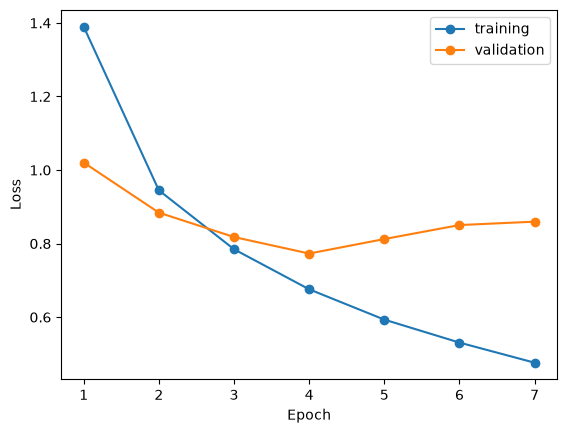

/tmp/ipykernel_524/3329818869.py:19: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  df_times_32_32_64_64_4layer.loc[len(df_times_32_32_64_64_4layer)] = [


Epoch,Aika (s)
1,9.01
2,5.93
3,5.94
4,5.84
5,5.86
6,5.84
7,5.84
Keski suoritusaika,6.68
Kokonaissuoritusaika,44.25


In [37]:
# Loss-arvojen visualisointi
epochs = range(1, len(history_32_32_64_64_4layer.history["loss"]) + 1)

plt.plot(epochs, history_32_32_64_64_4layer.history["loss"], marker="o", label="training")
plt.plot(epochs, history_32_32_64_64_4layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen
df_times_32_32_64_64_4layer = pd.DataFrame({
    "Epoch": range(1, len(timer_32_32_64_64_4layer.epoch_times) + 1),
    "Aika (s)": timer_32_32_64_64_4layer.epoch_times
})

# Keskimääräinen suoritusaika (poistetaan viimeiset 3 epochia)
df_times_32_32_64_64_4layer.loc[len(df_times_32_32_64_64_4layer)] = [
    "Keski suoritusaika",
    sum(timer_32_32_64_64_4layer.epoch_times[:-3]) / len(timer_32_32_64_64_4layer.epoch_times[:-3])
]

# Kokonaissuoritusaika
df_times_32_32_64_64_4layer.loc[len(df_times_32_32_64_64_4layer)] = [
    "Kokonaissuoritusaika",
    sum(timer_32_32_64_64_4layer.epoch_times)
]

# Näytetään dataframe ilman indeksejä
display(
    df_times_32_32_64_64_4layer.style
    .hide(axis="index")
    .format({"Aika (s)": "{:.2f}"})
)

#### 4.7.1 Mallin rakentaminen: 3 kerrosta 64/64/128

Katsotaan miten kolmikerroksinen malli toimii arvoilla 64/64/128.

In [38]:
keras.utils.set_random_seed(0)

model64_64_128_3layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 64 suodatinta
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 64
    layers.Conv2D(128, kernel_size=3, padding="same", activation="relu"), # Kolmas kerros 128 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 128
    layers.Flatten(),
    layers.Dense(10, activation="softmax") # 10 neuronia CIFAR-10:n luokkia varten
])

#### 4.7.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan Adam, joka päivittää mallin painokertoimia koulutuksen aikana pyrkien pienentämään loss-arvoa. Kokonaislukuluokituksen (0–9) vuoksi käytetään sparse_categorical_crossentropy-menetysfunktiota. Arviointimittarina toimii tarkkuus (accuracy). Koulutuksessa käytetään samaa EarlyStopping-menetelmää kuin muissa malleissa.

In [39]:
model64_64_128_3layer.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#### 4.7.3 Mallin kouluttaminen

In [40]:
# Tallennetaan historia myöhempää tarkastelua varten
history_64_64_128_3layer = model64_64_128_3layer.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[stop, timer_64_64_128_3layer]
)

# Tallennetaan ajat historiaan myöhempää tarkastelua varten
history_64_64_128_3layer.history["epoch_time_seconds"] = timer_64_64_128_3layer.epoch_times

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.5381 - loss: 1.3050 - val_accuracy: 0.6714 - val_loss: 0.9559
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6996 - loss: 0.8674 - val_accuracy: 0.7144 - val_loss: 0.8387
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7593 - loss: 0.7042 - val_accuracy: 0.7154 - val_loss: 0.8603
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8005 - loss: 0.5863 - val_accuracy: 0.7274 - val_loss: 0.8508
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8298 - loss: 0.4963 - val_accuracy: 0.7098 - val_loss: 0.9805


#### 4.7.4 Mallin arviointi

Vertaillaan CNN-mallien suorituskykyä testitarkkuuden (test accuracy), testihäviön (test loss), parametrimäärän ja koulutusajan perusteella. Lisäksi tarkastellaan parhaiden epochien koulutus- ja validointituloksia, jotta voidaan arvioida mallien tarkkuutta, ylisovittamista ja laskennallista tehokkuutta.

In [41]:
# Etsitään pienimmän validation lossin epoch
best_idx = np.argmin(history_64_64_128_3layer.history["val_loss"])

results_64_64_128 = [{
    "Malli": "64/64/128 (3 kerrosta)",
    "Paras epoch": best_idx + 1,
    "Training loss": history_64_64_128_3layer.history["loss"][best_idx],
    "Validation loss": history_64_64_128_3layer.history["val_loss"][best_idx],
    "Training accuracy": history_64_64_128_3layer.history["accuracy"][best_idx],
    "Validation accuracy": history_64_64_128_3layer.history["val_accuracy"][best_idx],
    "Koulutusaika (s)": sum(timer_64_64_128_3layer.epoch_times)
}]

df_results_64_64_128 = pd.DataFrame(results_64_64_128)

display(df_results_64_64_128.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,64/64/128 (3 kerrosta),2,0.8674,0.8387,0.6996,0.7144,31.9681


#### 4.7.5 Tulosten visualisointi ja analysointi

Visualisoidaan mallin harjoitusdatan menetys (loss) ja validointidatan menetys (validation loss). Lisäksi taulukoidaan epochien suoritusajat, keskimääräinen suoritusaika ja koulutuksen kokonaisaika.

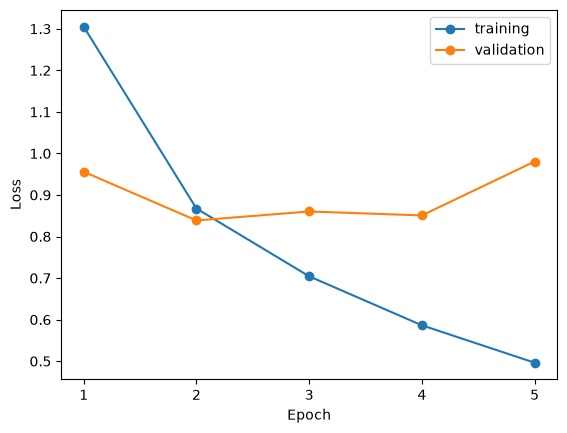

/tmp/ipykernel_524/3762835432.py:19: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  df_times_64_64_128_3layer.loc[len(df_times_64_64_128_3layer)] = [


Epoch,Aika (s)
1,8.72
2,5.83
3,5.82
4,5.79
5,5.80
Keski suoritusaika,7.28
Kokonaissuoritusaika,31.97


In [42]:
# Loss-arvojen visualisointi
epochs = range(1, len(history_64_64_128_3layer.history["loss"]) + 1)

plt.plot(epochs, history_64_64_128_3layer.history["loss"], marker="o", label="training")
plt.plot(epochs, history_64_64_128_3layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen
df_times_64_64_128_3layer = pd.DataFrame({
    "Epoch": range(1, len(timer_64_64_128_3layer.epoch_times) + 1),
    "Aika (s)": timer_64_64_128_3layer.epoch_times
})

# Keskimääräinen suoritusaika ilman kolmea viimeistä epochia
df_times_64_64_128_3layer.loc[len(df_times_64_64_128_3layer)] = [
    "Keski suoritusaika",
    sum(timer_64_64_128_3layer.epoch_times[:-3]) / len(timer_64_64_128_3layer.epoch_times[:-3])
]

# Kokonaissuoritusaika
df_times_64_64_128_3layer.loc[len(df_times_64_64_128_3layer)] = [
    "Kokonaissuoritusaika",
    sum(timer_64_64_128_3layer.epoch_times)
]

# Näytetään dataframe ilman indeksejä
display(
    df_times_64_64_128_3layer.style
    .hide(axis="index")
    .format({"Aika (s)": "{:.2f}"})
)

#### 4.7.6 Johtopäätökset

Mallin kerroksien nosto arvoille 64/64/128 laski koulutussuorituskykyä. Saa heikommat test ja val accuracyt, kuin 3 kerroksinen 32/32/64, ja hitaampi suorittaa. Lisäksi huomataan, että vaikka 2 kerroksisessa 64/128 saatiin parannusta tarkkuuteen, se kolmikerroksisessa laski. Tällä trendillä on turha kokeilla nelikerroksista 64/64/128/128-mallia. 

In [43]:
df_comparison = pd.concat([
    df_results_16_32,
    df_results_32_64,
    df_results_64_128,
    df_results_32_32_64,
    df_results_64_64_128,
    df_results_32_32_64_64
], ignore_index=True)

display(df_comparison.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,16/32 (2 kerrosta),12,0.7416,0.9256,0.7468,0.6862,78.0981
1,32/64 (2 kerrosta),6,0.7345,0.8881,0.7472,0.7034,50.5930
2,64/128 (2 kerrosta),5,0.6641,0.8685,0.7743,0.7180,45.3581
3,32/32/64 (3 kerrosta),4,0.7297,0.8225,0.7515,0.7258,41.5618
4,64/64/128 (3 kerrosta),2,0.8674,0.8387,0.6996,0.7144,31.9681
5,32/32/64/64 (4 kerrosta),4,0.6757,0.7730,0.7640,0.7452,44.2509


### 4.8 RBG-standardoinnin vaikutus CNN-malleihin

Valitaan parhaimmat kaksi-, kolme- ja nelikerroksiset mallit 32/64, 32/32/64 ja 32/32/64/64, ja vertaillaan niiden supritusta RBG standardoinnin jälkeen.

### 4.8.1 Mallien luonti ja koulutus

In [44]:
# Standardoinnilla vertailtavat arkkitehtuurit
models_comparison = {
    "32/64": model32_64_2layer,
    "32/32/64": model32_32_64_3layer,
    "32/32/64/64": model32_32_64_64_4layer
}

std_models = {}
std_histories = {}
std_timers = {}

for name, base_model in models_comparison.items():

    keras.utils.set_random_seed(0)

    # Kopioidaan vain arkkitehtuuri, ei koulutettuja painoja
    model = keras.models.clone_model(base_model)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    timer = EpochTimer()
    
    history = model.fit(
        x_train_std,
        y_train,
        epochs=20,
        batch_size=32,
        validation_split=0.1,
        callbacks=[stop, timer],
        verbose=1
    )

    std_models[name] = model
    std_histories[name] = history
    std_timers[name] = timer


Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5479 - loss: 1.2866 - val_accuracy: 0.6522 - val_loss: 1.0024
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6746 - loss: 0.9465 - val_accuracy: 0.6982 - val_loss: 0.8882
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7207 - loss: 0.8126 - val_accuracy: 0.7080 - val_loss: 0.8661
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7549 - loss: 0.7208 - val_accuracy: 0.7094 - val_loss: 0.8694
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7787 - loss: 0.6500 - val_accuracy: 0.7088 - val_loss: 0.8864
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7984 - loss: 0.5921 - val_accuracy: 0.7068 - val_loss: 0.9144
Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.5562 - loss: 1.2560 - val_accuracy: 0.6880 - val_loss: 0.9265
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6996 - loss: 0.8719 - 

In [45]:
# RGB-standardoitujen mallien tulokset
std_results = []

for name, history in std_histories.items():
    best_idx = np.argmin(history.history["val_loss"])

    std_results.append({
        "Malli": f"{name} (RGB-standardoitu)",
        "Paras epoch": best_idx + 1,
        "Training loss": history.history["loss"][best_idx],
        "Validation loss": history.history["val_loss"][best_idx],
        "Training accuracy": history.history["accuracy"][best_idx],
        "Validation accuracy": history.history["val_accuracy"][best_idx],
        "Koulutusaika (s)": sum(std_timers[name].epoch_times)
    })

df_results_std = pd.DataFrame(std_results)

# Vertailuun vain kolme alkuperäistä ja kolme standardoitua mallia
df_comparison_rgb = pd.concat([
    df_results_32_64.assign(Malli="32/64 (normalisoitu)"),
    df_results_std[df_results_std["Malli"] == "32/64 (RGB-standardoitu)"],

    df_results_32_32_64.assign(Malli="32/32/64 (normalisoitu)"),
    df_results_std[df_results_std["Malli"] == "32/32/64 (RGB-standardoitu)"],

    df_results_32_32_64_64.assign(Malli="32/32/64/64 (normalisoitu)"),
    df_results_std[df_results_std["Malli"] == "32/32/64/64 (RGB-standardoitu)"]
], ignore_index=True)

display(df_comparison_rgb.round(4))

,Malli,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,32/64 (normalisoitu),6,0.7345,0.8881,0.7472,0.7034,50.5930
1,32/64 (RGB-standardoitu),3,0.8126,0.8661,0.7207,0.7080,32.4140
2,32/32/64 (normalisoitu),4,0.7297,0.8225,0.7515,0.7258,41.5618
3,32/32/64 (RGB-standardoitu),3,0.7274,0.8122,0.7495,0.7346,35.6178
4,32/32/64/64 (normalisoitu),4,0.6757,0.7730,0.7640,0.7452,44.2509
5,32/32/64/64 (RGB-standardoitu),4,0.5761,0.8048,0.8006,0.7532,43.4262


### 4.8.3 Johtopäätökset

RBG-standardointi parantaa lineaarisesti kerroksittain validointi tarkkuutta: 32/64-mallilla 0,46 prosenttiyksikköä, 32/32/64-mallilla 0,66 prosenttiyksikköä ja 32/32/64/64-mallilla 0,80 prosenttiyksikköä. Tästä voidaan päätellä, että mallien suorituskyky paranee standartoiduilla RBG arvoilla. 

### 4.9 Johtopäätökset

Mallien vertailussa havaittiin, että suodattimien ja kerrosten määrän lisääminen ei automaattisesti paranna tarkkuutta. Kaksikerroksisista malleista paras validointitarkkuus (71,80 %) saavutettiin `64/128`-mallilla. Kolmikerroksinen `32/32/64`-malli saavutti 72,58 %:n validointitarkkuuden, mikä oli 2,24 prosenttiyksikköä parempi kuin kaksikerroksisella `32/64`-mallilla. Samalla koulutusaika lyheni hieman.

Suurempi kolmikerroksinen `64/64/128`-malli ei parantanut validointitarkkuutta (71,44 %), vaikka siinä oli enemmän parametreja. Nelikerroksinen `32/32/64/64`-malli saavutti kuitenkin paremman validointitarkkuuden (74,52 %) ja pienemmän validation loss -arvon (0,7730). Koulutusaika kasvoi kolmikerroksiseen `32/32/64`-malliin verrattuna vain vähän.

RGB-standardointi paransi kaikkien kolmen vertailtavan mallin validointitarkkuutta 0,46–0,88 prosenttiyksikköä. Suurin parannus saavutettiin kolmikerroksisella mallilla, joten standardoinnin hyöty ei kasvanut suoraan kerrosmäärän mukana. Myös kokonaiskoulutusajat lyhenivät hieman tai merkittävästi mallista riippuen. Tähän vaikutti kuitenkin osittain EarlyStopping-menetelmän pysäyttäessä koulutukset eri epocheilla, joten standardoinnin suoraa vaikutusta koulutusnopeuteen pitäisi tutkia tarkemmin. Sitä ei tehdä tässä notebookissa.

Jatkokehitykseen valitaan RGB-standardoitu `32/32/64/64`-malli, koska se saavutti parhaan validointitarkkuuden (75,32 %) kohtuullisella koulutusajalla. Seuraavaksi voidaan tutkia muiden optimointimenetelmien ja regularisointitekniikoiden vaikutusta mallin suorituskykyyn.

### 4.10 CNN-mallien parametrimäärien vertailu

#### 4.10.1 Mallien rakenteet ja parametrimäärät

Tulostetaan kaikkien kuuden alkuperäisen ja kolmen RGB-standardoidun CNN-mallin rakenteet `model.summary()`-menetelmällä.

Vertaillaan konvoluutiokerrosten määrää, Conv2D- ja Dense-kerrosten parametrimääriä sekä mallien kokonaisparametrimääriä. Ei sisällä RGB stantardoituja, kun parametrimäärät pysyvät samoina

In [46]:
# Kaikki koulutetut CNN-mallit
models_params = {
    "16/32": model16_32_2layer,
    "32/64": model32_64_2layer,
    "64/128": model64_128_2layer,
    "32/32/64": model32_32_64_3layer,
    "64/64/128": model64_64_128_3layer,
    "32/32/64/64": model32_32_64_64_4layer
}

parameter_results = []

for name, model in models_params.items():

    print(f"\n{'=' * 60}")
    print(f"CNN-malli: {name}")
    print(f"{'=' * 60}")

    # Tulostetaan mallin rakenne
    model.summary()

    # Lasketaan konvoluutiokerrosten parametrit
    conv_layers = [
        layer for layer in model.layers
        if isinstance(layer, keras.layers.Conv2D)
    ]

    conv_params = sum(
        layer.count_params() for layer in conv_layers
    )

    # Lasketaan Dense-kerrosten parametrit
    dense_params = sum(
        layer.count_params()
        for layer in model.layers
        if isinstance(layer, keras.layers.Dense)
    )

    parameter_results.append({
        "Malli": name,
        "Conv2D-kerroksia": len(conv_layers),
        "Conv2D-parametrit": conv_params,
        "Dense-parametrit": dense_params,
        "Parametrit yhteensä": model.count_params()
    })

# Muodostetaan vertailutaulukko
df_parameters = pd.DataFrame(parameter_results)

# Suhteutetaan parametrimäärät pienimpään malliin
min_params = df_parameters["Parametrit yhteensä"].min()

df_parameters["Suhde pienimpään"] = (
    df_parameters["Parametrit yhteensä"] / min_params
)

display(
    df_parameters.style
    .hide(axis="index")
    .format({
        "Conv2D-parametrit": "{:,}",
        "Dense-parametrit": "{:,}",
        "Parametrit yhteensä": "{:,}",
        "Suhde pienimpään": "{:.2f}×"
    })
)

# Tulostetaan yhteenveto
smallest = df_parameters.loc[
    df_parameters["Parametrit yhteensä"].idxmin()
]

largest = df_parameters.loc[
    df_parameters["Parametrit yhteensä"].idxmax()
]


CNN-malli: 16/32


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,736 (299.75 KB)

 Trainable params: 25,578 (99.91 KB)

...

 Total params: 319,616 (1.22 MB)

 Trainable params: 106,538 (416.16 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 213,078 (832.34 KB)

Malli,Conv2D-kerroksia,Conv2D-parametrit,Dense-parametrit,Parametrit yhteensä,Suhde pienimpään
16/32,2,"5,088","20,490","25,578",1.00×
32/64,2,"19,392","40,970","60,362",2.36×
64/128,2,"75,648","81,930","157,578",6.16×
32/32/64,3,"28,640","40,970","69,610",2.72×
64/64/128,3,"112,576","81,930","194,506",7.60×
32/32/64/64,4,"65,568","40,970","106,538",4.17×


### 4.10.1 Johtopäätökset

Parametrien määrä kasvaa neuronien määrien mukaan ja kerroksien mukaan. Vaikka pienimpään malliin verrattuna 4 kerroksinen parhaiten suoriutunut 32/32/64/64-mallin parametrit vain nelinkertaistu ja suoritusaika pysyi kohtuullisena, kun koulutustuloksiin päästiin lyhyemmillä koulutuskierroksilla.

## 4.11 Regularisointikokeilut (RGB-standardoitu data)

### 4.11.1 Baseline (4 kerrosta, 20 ep)



 Baseline (4 kerrosta, 20 ep) 
Epoch 1/20
1407/1407 - 8s - 6ms/step - accuracy: 0.5516 - loss: 1.2703 - val_accuracy: 0.6840 - val_loss: 0.9099
Epoch 2/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7088 - loss: 0.8374 - val_accuracy: 0.7292 - val_loss: 0.8084
Epoch 3/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7622 - loss: 0.6825 - val_accuracy: 0.7312 - val_loss: 0.8284
Epoch 4/20
1407/1407 - 6s - 4ms/step - accuracy: 0.8006 - loss: 0.5761 - val_accuracy: 0.7532 - val_loss: 0.8048
Epoch 5/20
1407/1407 - 6s - 4ms/step - accuracy: 0.8278 - loss: 0.4901 - val_accuracy: 0.7424 - val_loss: 0.8639
Epoch 6/20
1407/1407 - 6s - 4ms/step - accuracy: 0.8513 - loss: 0.4226 - val_accuracy: 0.7300 - val_loss: 0.9935
Epoch 7/20
1407/1407 - 6s - 4ms/step - accuracy: 0.8683 - loss: 0.3732 - val_accuracy: 0.7260 - val_loss: 1.0999


2026-10-28 14:38:50.277391: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Baseline,73.12%,0.8545,"106,538",7,4


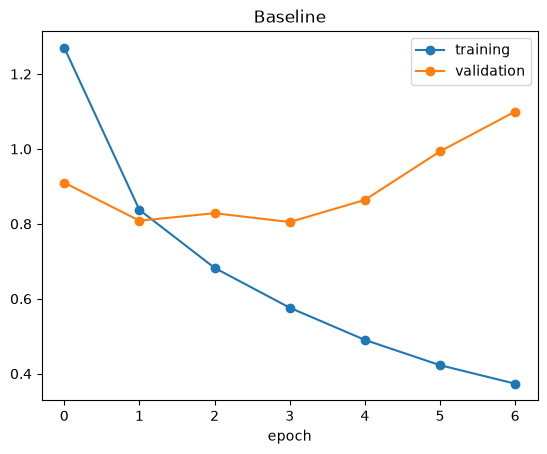

Train accuracy (viimeinen ep): 86.83%
Val accuracy (paras):          75.32%


In [48]:
print("\n Baseline (4 kerrosta, 20 ep) ")
keras.utils.set_random_seed(0)

# Standardoidaan testidata koulutusdatasta lasketuilla RGB-arvoilla
x_test_std = (x_test - rgb_mean) / rgb_std

model_baseline = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

model_baseline.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

timer_baseline = EpochTimer()
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history_baseline = model_baseline.fit(
    x_train_std, y_train,
    epochs=20,
    validation_split=0.1,
    callbacks=[early_stop, timer_baseline],
    verbose=2
)

loss_baseline, acc_baseline = model_baseline.evaluate(x_test_std, y_test, verbose=0)
best_epoch_baseline = int(np.argmin(history_baseline.history["val_loss"])) + 1

df_baseline = pd.DataFrame([{
    "Malli": "Baseline",
    "Test accuracy": acc_baseline,
    "Test loss": loss_baseline,
    "Parametrit": model_baseline.count_params(),
    "Epookkeja": len(timer_baseline.epoch_times),
    "Paras epookki": best_epoch_baseline,
}])
display(df_baseline.style.hide(axis="index").format({"Test accuracy": "{:.2%}", "Test loss": "{:.4f}", "Parametrit": "{:,}"}))

plt.plot(history_baseline.history["loss"], marker="o", label="training")
plt.plot(history_baseline.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.title("Baseline")
plt.legend()
plt.show()

print(f"Train accuracy (viimeinen ep): {history_baseline.history['accuracy'][-1]:.2%}")
print(f"Val accuracy (paras):          {max(history_baseline.history['val_accuracy']):.2%}")

### 4.11.2 Dropout
Lisätään verkkoon Dropout-kerros (0.3), joka sammuttaa satunnaisesti 30% neuroneista koulutuksen aikana. Tämän pitäisi estää verkkoa nojaamasta liikaa yksittäisiin neuroneihin ja vähentää ylisovittumista.


=== Dropout 0.2 ===
Epoch 1/20


2026-10-28 14:39:00.680576: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


1407/1407 - 11s - 8ms/step - accuracy: 0.5489 - loss: 1.2801 - val_accuracy: 0.6854 - val_loss: 0.9183
Epoch 2/20
1407/1407 - 6s - 4ms/step - accuracy: 0.6985 - loss: 0.8659 - val_accuracy: 0.7420 - val_loss: 0.7572
Epoch 3/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7496 - loss: 0.7237 - val_accuracy: 0.7546 - val_loss: 0.7222
Epoch 4/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7766 - loss: 0.6408 - val_accuracy: 0.7636 - val_loss: 0.7131
Epoch 5/20
1407/1407 - 6s - 4ms/step - accuracy: 0.8009 - loss: 0.5703 - val_accuracy: 0.7632 - val_loss: 0.7252
Epoch 6/20
1407/1407 - 6s - 4ms/step - accuracy: 0.8211 - loss: 0.5135 - val_accuracy: 0.7590 - val_loss: 0.7486
Epoch 7/20
1407/1407 - 6s - 4ms/step - accuracy: 0.8342 - loss: 0.4707 - val_accuracy: 0.7524 - val_loss: 0.7893


Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Dropout 0.2,74.84%,0.7531,"106,538",7,4


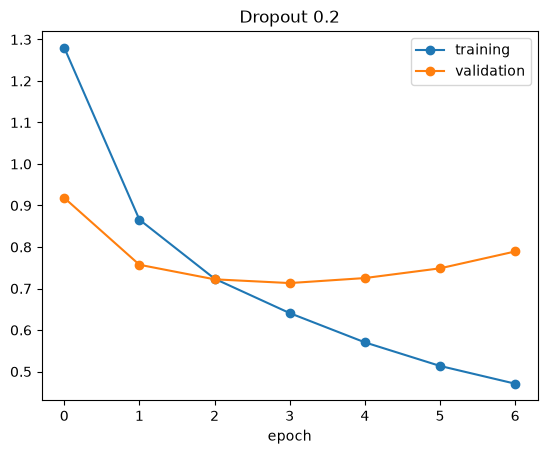

Train accuracy (viimeinen ep): 83.42%
Val accuracy (paras):          76.36%

=== Dropout 0.3 ===
Epoch 1/20
1407/1407 - 9s - 7ms/step - accuracy: 0.5314 - loss: 1.3161 - val_accuracy: 0.6754 - val_loss: 0.9281
Epoch 2/20
1407/1407 - 6s - 4ms/step - accuracy: 0.6865 - loss: 0.9057 - val_accuracy: 0.7248 - val_loss: 0.7993
Epoch 3/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7299 - loss: 0.7722 - val_accuracy: 0.7444 - val_loss: 0.7379
Epoch 4/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7628 - loss: 0.6848 - val_accuracy: 0.7540 - val_loss: 0.7263
Epoch 5/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7853 - loss: 0.6187 - val_accuracy: 0.7628 - val_loss: 0.7011
Epoch 6/20
1407/1407 - 6s - 4ms/step - accuracy: 0.8007 - loss: 0.5712 - val_accuracy: 0.7518 - val_loss: 0.7353
Epoch 7/20
1407/1407 - 6s - 4ms/step - accuracy: 0.8121 - loss: 0.5317 - val_accuracy: 0.7710 - val_loss: 0.6954
Epoch 8/20
1407/1407 - 6s - 4ms/step - accuracy: 0.8234 - loss: 0.4959 - val_accuracy: 0.7544 - val_loss: 0.7372

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Dropout 0.3,75.79%,0.7485,"106,538",10,7


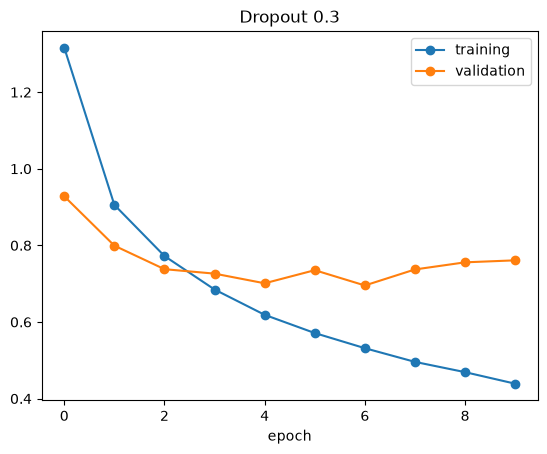

Train accuracy (viimeinen ep): 84.51%
Val accuracy (paras):          77.10%

=== Dropout 0.5 ===
Epoch 1/20
1407/1407 - 9s - 7ms/step - accuracy: 0.5141 - loss: 1.3637 - val_accuracy: 0.6570 - val_loss: 0.9825
Epoch 2/20
1407/1407 - 6s - 4ms/step - accuracy: 0.6667 - loss: 0.9630 - val_accuracy: 0.7224 - val_loss: 0.8135
Epoch 3/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7110 - loss: 0.8307 - val_accuracy: 0.7468 - val_loss: 0.7429
Epoch 4/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7325 - loss: 0.7573 - val_accuracy: 0.7598 - val_loss: 0.7184
Epoch 5/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7521 - loss: 0.7036 - val_accuracy: 0.7656 - val_loss: 0.7044
Epoch 6/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7668 - loss: 0.6643 - val_accuracy: 0.7704 - val_loss: 0.7001
Epoch 7/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7782 - loss: 0.6336 - val_accuracy: 0.7600 - val_loss: 0.7047
Epoch 8/20
1407/1407 - 6s - 4ms/step - accuracy: 0.7858 - loss: 0.6027 - val_accuracy: 0.7742 - val_loss: 0.6842

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Dropout 0.5,77.17%,0.7074,"106,538",15,12


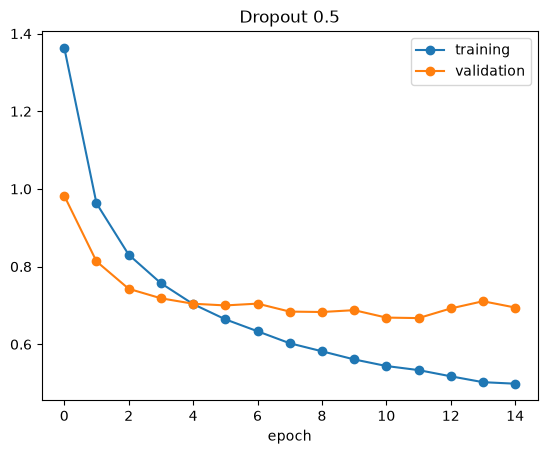

Train accuracy (viimeinen ep): 82.26%
Val accuracy (paras):          78.16%


In [49]:
def build_dropout(dropout_rate):
    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
        layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
        layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dropout(dropout_rate),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

for rate in [0.2, 0.3, 0.5]:
    print(f"\n=== Dropout {rate} ===")
    keras.utils.set_random_seed(0)
    
    model = build_dropout(rate)
    timer = EpochTimer()
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    
    history = model.fit(x_train_std, y_train, epochs=20, validation_split=0.1, callbacks=[early_stop, timer], verbose=2)
    
    loss, acc = model.evaluate(x_test_std, y_test, verbose=0)
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    
    df = pd.DataFrame([{
        "Malli": f"Dropout {rate}",
        "Test accuracy": acc,
        "Test loss": loss,
        "Parametrit": model.count_params(),
        "Epookkeja": len(timer.epoch_times),
        "Paras epookki": best_epoch,
    }])
    display(df.style.hide(axis="index").format({"Test accuracy": "{:.2%}", "Test loss": "{:.4f}", "Parametrit": "{:,}"}))
    
    plt.plot(history.history["loss"], marker="o", label="training")
    plt.plot(history.history["val_loss"], marker="o", label="validation")
    plt.xlabel("epoch")
    plt.title(f"Dropout {rate}")
    plt.legend()
    plt.show()
    
    print(f"Train accuracy (viimeinen ep): {history.history['accuracy'][-1]:.2%}")
    print(f"Val accuracy (paras):          {max(history.history['val_accuracy']):.2%}")

### 4.11.3 Data augmentation
Kokeillaan datan monipuolistamista kääntämällä kuvia vaakasuunnassa (RandomFlip) ja siirtämällä niitä hieman (RandomTranslation). Tämä pakottaa mallin oppimaan yleispätevämpiä piirteitä sen sijaan, että se opettelisi harjoituskuvat ulkoa.


=== RandomTranslation 0.05 ===
Epoch 1/20
1407/1407 - 13s - 9ms/step - accuracy: 0.5216 - loss: 1.3470 - val_accuracy: 0.6516 - val_loss: 1.0500
Epoch 2/20
1407/1407 - 8s - 6ms/step - accuracy: 0.6698 - loss: 0.9488 - val_accuracy: 0.6960 - val_loss: 0.9164
Epoch 3/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7202 - loss: 0.8145 - val_accuracy: 0.7254 - val_loss: 0.8412
Epoch 4/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7428 - loss: 0.7423 - val_accuracy: 0.7456 - val_loss: 0.7851
Epoch 5/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7605 - loss: 0.6948 - val_accuracy: 0.7532 - val_loss: 0.7698
Epoch 6/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7736 - loss: 0.6543 - val_accuracy: 0.7594 - val_loss: 0.7554
Epoch 7/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7814 - loss: 0.6285 - val_accuracy: 0.7632 - val_loss: 0.7395
Epoch 8/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7902 - loss: 0.6070 - val_accuracy: 0.7756 - val_loss: 0.7261
Epoch 9/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7961 - loss:

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Aug 0.05,77.38%,0.7315,"106,538",15,12


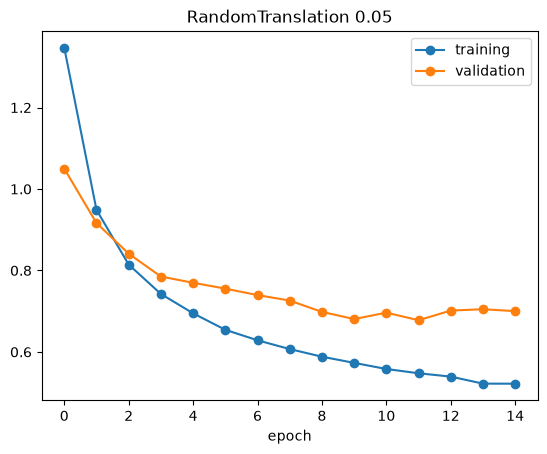

Train accuracy (viimeinen ep): 81.82%
Val accuracy (paras):          79.32%

=== RandomTranslation 0.1 ===
Epoch 1/20
1407/1407 - 9s - 6ms/step - accuracy: 0.4929 - loss: 1.4133 - val_accuracy: 0.6310 - val_loss: 1.0705
Epoch 2/20
1407/1407 - 8s - 6ms/step - accuracy: 0.6422 - loss: 1.0183 - val_accuracy: 0.7112 - val_loss: 0.8555
Epoch 3/20
1407/1407 - 8s - 6ms/step - accuracy: 0.6920 - loss: 0.8908 - val_accuracy: 0.7232 - val_loss: 0.8149
Epoch 4/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7153 - loss: 0.8212 - val_accuracy: 0.7436 - val_loss: 0.7710
Epoch 5/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7336 - loss: 0.7679 - val_accuracy: 0.7466 - val_loss: 0.7692
Epoch 6/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7446 - loss: 0.7332 - val_accuracy: 0.7574 - val_loss: 0.7395
Epoch 7/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7556 - loss: 0.7027 - val_accuracy: 0.7742 - val_loss: 0.6980
Epoch 8/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7628 - loss: 0.6861 - val_accuracy: 0.7872 - val_lo

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Aug 0.1,77.59%,0.6791,"106,538",11,8


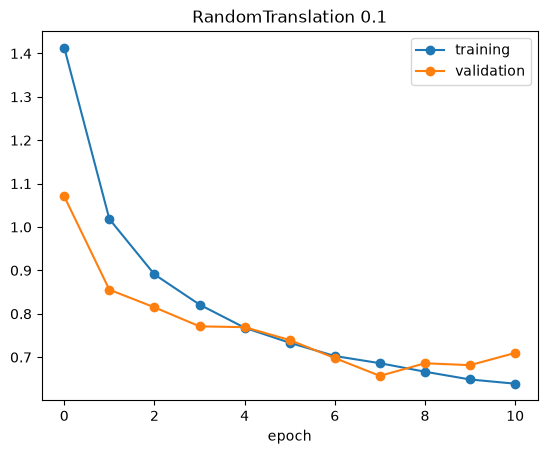

Train accuracy (viimeinen ep): 77.94%
Val accuracy (paras):          78.72%

=== RandomTranslation 0.2 ===
Epoch 1/20
1407/1407 - 9s - 6ms/step - accuracy: 0.4336 - loss: 1.5579 - val_accuracy: 0.5888 - val_loss: 1.1536
Epoch 2/20
1407/1407 - 8s - 6ms/step - accuracy: 0.5673 - loss: 1.2191 - val_accuracy: 0.6522 - val_loss: 1.0170
Epoch 3/20
1407/1407 - 8s - 6ms/step - accuracy: 0.6214 - loss: 1.0671 - val_accuracy: 0.6962 - val_loss: 0.8864
Epoch 4/20
1407/1407 - 8s - 6ms/step - accuracy: 0.6557 - loss: 0.9750 - val_accuracy: 0.7238 - val_loss: 0.8162
Epoch 5/20
1407/1407 - 8s - 6ms/step - accuracy: 0.6789 - loss: 0.9246 - val_accuracy: 0.7362 - val_loss: 0.8074
Epoch 6/20
1407/1407 - 8s - 6ms/step - accuracy: 0.6976 - loss: 0.8743 - val_accuracy: 0.7396 - val_loss: 0.7845
Epoch 7/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7064 - loss: 0.8474 - val_accuracy: 0.7488 - val_loss: 0.7612
Epoch 8/20
1407/1407 - 8s - 6ms/step - accuracy: 0.7148 - loss: 0.8247 - val_accuracy: 0.7414 - val_lo

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Aug 0.2,77.55%,0.6866,"106,538",16,13


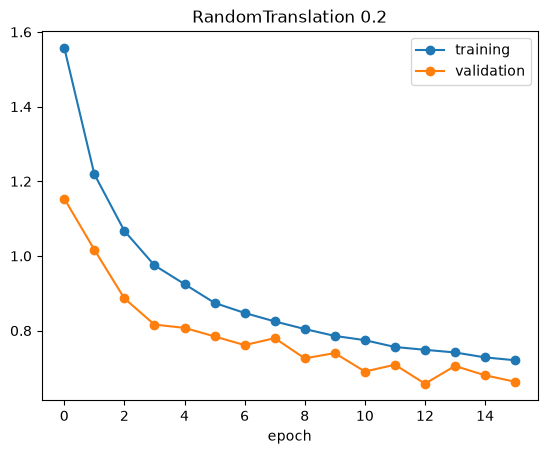

Train accuracy (viimeinen ep): 75.19%
Val accuracy (paras):          78.26%


In [50]:
def build_augmentation(translation):
    data_augmentation = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomTranslation(translation, translation),
    ])

    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        data_augmentation,
        layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
        layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
        layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

for t in [0.05, 0.1, 0.2]:
    print(f"\n=== RandomTranslation {t} ===")
    keras.utils.set_random_seed(0)
    
    model = build_augmentation(t)
    timer = EpochTimer()
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    
    history = model.fit(x_train_std, y_train, epochs=20, validation_split=0.1, callbacks=[early_stop, timer], verbose=2)
    
    loss, acc = model.evaluate(x_test_std, y_test, verbose=0)
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    
    df = pd.DataFrame([{
        "Malli": f"Aug {t}",
        "Test accuracy": acc,
        "Test loss": loss,
        "Parametrit": model.count_params(),
        "Epookkeja": len(timer.epoch_times),
        "Paras epookki": best_epoch,
    }])
    display(df.style.hide(axis="index").format({"Test accuracy": "{:.2%}", "Test loss": "{:.4f}", "Parametrit": "{:,}"}))
    
    plt.plot(history.history["loss"], marker="o", label="training")
    plt.plot(history.history["val_loss"], marker="o", label="validation")
    plt.xlabel("epoch")
    plt.title(f"RandomTranslation {t}")
    plt.legend()
    plt.show()
    
    print(f"Train accuracy (viimeinen ep): {history.history['accuracy'][-1]:.2%}")
    print(f"Val accuracy (paras):          {max(history.history['val_accuracy']):.2%}")

#### 4.11.3.1 Augmentaatio (40 ep)

20 epookkia ei riittänyt konvergoitumiseen (paras epookki 20), joten ajetaan Aug 0.1.

In [51]:
print("\n=== RandomTranslation 0.1 (40 ep, patience=6) ===")
keras.utils.set_random_seed(0)

model_aug_40 = build_augmentation(0.1)
timer_aug_40 = EpochTimer()
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)

history_aug_40 = model_aug_40.fit(
    x_train_std, y_train, 
    epochs=40, 
    validation_split=0.1, 
    callbacks=[early_stop, timer_aug_40], 
    verbose=2
)

loss_aug_40, acc_aug_40 = model_aug_40.evaluate(x_test_std, y_test, verbose=0)
best_epoch_aug_40 = int(np.argmin(history_aug_40.history["val_loss"])) + 1

df_aug_40 = pd.DataFrame([{
    "Malli": "Aug 0.1 (40 ep)",
    "Test accuracy": acc_aug_40,
    "Test loss": loss_aug_40,
    "Parametrit": model_aug_40.count_params(),
    "Epookkeja": len(timer_aug_40.epoch_times),
    "Paras epookki": best_epoch_aug_40,
}])
display(df_aug_40.style.hide(axis="index").format({"Test accuracy": "{:.2%}", "Test loss": "{:.4f}", "Parametrit": "{:,}"}))


=== RandomTranslation 0.1 (40 ep, patience=6) ===
Epoch 1/40
1407/1407 - 10s - 7ms/step - accuracy: 0.4987 - loss: 1.4039 - val_accuracy: 0.6490 - val_loss: 1.0306
Epoch 2/40
1407/1407 - 8s - 6ms/step - accuracy: 0.6493 - loss: 1.0077 - val_accuracy: 0.6986 - val_loss: 0.9016
Epoch 3/40
1407/1407 - 9s - 6ms/step - accuracy: 0.6896 - loss: 0.8885 - val_accuracy: 0.7066 - val_loss: 0.8816
Epoch 4/40
1407/1407 - 8s - 6ms/step - accuracy: 0.7151 - loss: 0.8174 - val_accuracy: 0.7484 - val_loss: 0.7623
Epoch 5/40
1407/1407 - 8s - 6ms/step - accuracy: 0.7345 - loss: 0.7622 - val_accuracy: 0.7596 - val_loss: 0.7374
Epoch 6/40
1407/1407 - 8s - 6ms/step - accuracy: 0.7481 - loss: 0.7236 - val_accuracy: 0.7652 - val_loss: 0.7055
Epoch 7/40
1407/1407 - 8s - 6ms/step - accuracy: 0.7548 - loss: 0.7023 - val_accuracy: 0.7822 - val_loss: 0.6833
Epoch 8/40
1407/1407 - 8s - 6ms/step - accuracy: 0.7636 - loss: 0.6787 - val_accuracy: 0.7824 - val_loss: 0.6964
Epoch 9/40
1407/1407 - 8s - 6ms/step - accur

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Aug 0.1 (40 ep),78.84%,0.6646,"106,538",21,15


### 4.11.4 Batch Normalization
Lisätään BatchNormalization-kerrokset konvoluutiokerrosten jälkeen. Tämä normalisoi kerrosten väliset syötteet, mikä vakauttaa ja nopeuttaa oppimista. 


 BatchNorm momentum 0.9 
Epoch 1/20
1407/1407 - 11s - 8ms/step - accuracy: 0.5409 - loss: 1.3235 - val_accuracy: 0.6870 - val_loss: 0.9305
Epoch 2/20
1407/1407 - 6s - 5ms/step - accuracy: 0.7001 - loss: 0.8670 - val_accuracy: 0.7232 - val_loss: 0.8070
Epoch 3/20
1407/1407 - 6s - 5ms/step - accuracy: 0.7540 - loss: 0.7139 - val_accuracy: 0.7504 - val_loss: 0.7289
Epoch 4/20
1407/1407 - 6s - 5ms/step - accuracy: 0.7929 - loss: 0.6052 - val_accuracy: 0.7658 - val_loss: 0.6881
Epoch 5/20
1407/1407 - 6s - 5ms/step - accuracy: 0.8257 - loss: 0.5149 - val_accuracy: 0.7616 - val_loss: 0.7146
Epoch 6/20
1407/1407 - 6s - 5ms/step - accuracy: 0.8524 - loss: 0.4364 - val_accuracy: 0.7594 - val_loss: 0.7493
Epoch 7/20
1407/1407 - 6s - 4ms/step - accuracy: 0.8775 - loss: 0.3689 - val_accuracy: 0.7524 - val_loss: 0.8243


Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
BN 0.9,75.75%,0.7221,"107,306",7,4


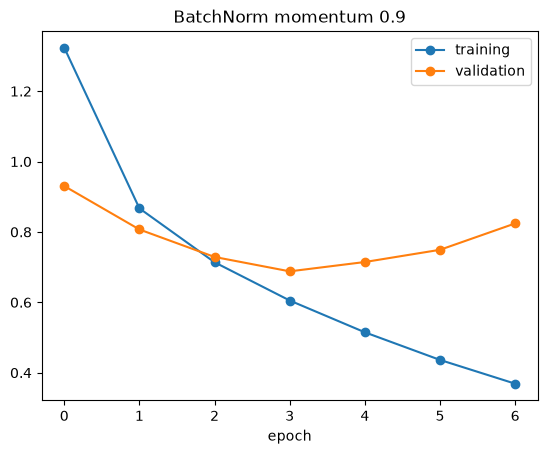

Train accuracy (viimeinen ep): 87.75%
Val accuracy (paras):          76.58%

 BatchNorm momentum 0.99 
Epoch 1/20
1407/1407 - 11s - 8ms/step - accuracy: 0.5409 - loss: 1.3235 - val_accuracy: 0.6710 - val_loss: 0.9840
Epoch 2/20
1407/1407 - 6s - 5ms/step - accuracy: 0.7001 - loss: 0.8670 - val_accuracy: 0.7004 - val_loss: 0.8814
Epoch 3/20
1407/1407 - 6s - 5ms/step - accuracy: 0.7540 - loss: 0.7139 - val_accuracy: 0.7186 - val_loss: 0.8362
Epoch 4/20
1407/1407 - 6s - 5ms/step - accuracy: 0.7929 - loss: 0.6052 - val_accuracy: 0.7404 - val_loss: 0.7870
Epoch 5/20
1407/1407 - 6s - 5ms/step - accuracy: 0.8257 - loss: 0.5149 - val_accuracy: 0.7294 - val_loss: 0.8471
Epoch 6/20
1407/1407 - 6s - 5ms/step - accuracy: 0.8524 - loss: 0.4364 - val_accuracy: 0.7190 - val_loss: 0.9289
Epoch 7/20
1407/1407 - 6s - 5ms/step - accuracy: 0.8775 - loss: 0.3689 - val_accuracy: 0.7010 - val_loss: 1.0636


Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
BN 0.99,73.19%,0.8182,"107,306",7,4


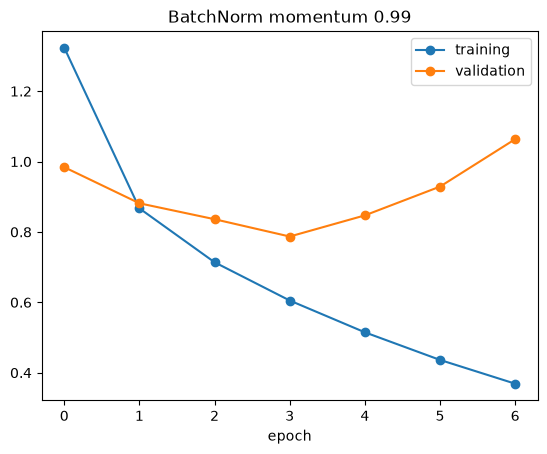

Train accuracy (viimeinen ep): 87.75%
Val accuracy (paras):          74.04%

 BatchNorm momentum 0.999 
Epoch 1/20
1407/1407 - 11s - 8ms/step - accuracy: 0.5409 - loss: 1.3235 - val_accuracy: 0.6342 - val_loss: 1.0665
Epoch 2/20
1407/1407 - 6s - 5ms/step - accuracy: 0.7001 - loss: 0.8670 - val_accuracy: 0.6768 - val_loss: 0.9290
Epoch 3/20
1407/1407 - 6s - 5ms/step - accuracy: 0.7540 - loss: 0.7139 - val_accuracy: 0.6868 - val_loss: 0.9668
Epoch 4/20
1407/1407 - 6s - 5ms/step - accuracy: 0.7929 - loss: 0.6052 - val_accuracy: 0.6990 - val_loss: 0.9524
Epoch 5/20
1407/1407 - 6s - 5ms/step - accuracy: 0.8257 - loss: 0.5149 - val_accuracy: 0.7088 - val_loss: 0.9821


Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
BN 0.999,67.21%,0.9600,"107,306",5,2


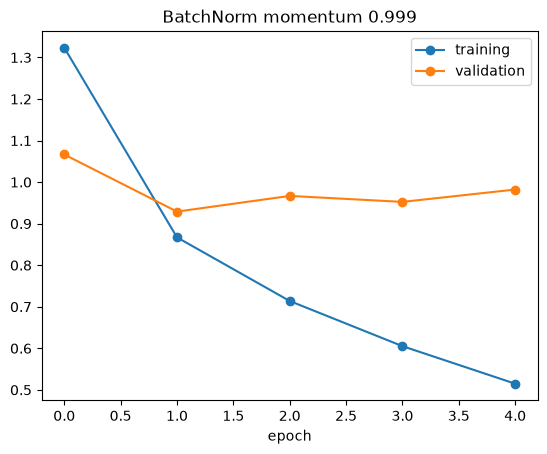

Train accuracy (viimeinen ep): 82.57%
Val accuracy (paras):          70.88%


In [52]:
def build_batchnorm(momentum):
    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.Conv2D(32, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(64, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.Conv2D(64, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

for mom in [0.9, 0.99, 0.999]:
    print(f"\n BatchNorm momentum {mom} ")
    keras.utils.set_random_seed(0)
    
    model = build_batchnorm(mom)
    timer = EpochTimer()
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    
    history = model.fit(x_train_std, y_train, epochs=20, validation_split=0.1, callbacks=[early_stop, timer], verbose=2)
    
    loss, acc = model.evaluate(x_test_std, y_test, verbose=0)
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    
    df = pd.DataFrame([{
        "Malli": f"BN {mom}",
        "Test accuracy": acc,
        "Test loss": loss,
        "Parametrit": model.count_params(),
        "Epookkeja": len(timer.epoch_times),
        "Paras epookki": best_epoch,
    }])
    display(df.style.hide(axis="index").format({"Test accuracy": "{:.2%}", "Test loss": "{:.4f}", "Parametrit": "{:,}"}))
    
    plt.plot(history.history["loss"], marker="o", label="training")
    plt.plot(history.history["val_loss"], marker="o", label="validation")
    plt.xlabel("epoch")
    plt.title(f"BatchNorm momentum {mom}")
    plt.legend()
    plt.show()
    
    print(f"Train accuracy (viimeinen ep): {history.history['accuracy'][-1]:.2%}")
    print(f"Val accuracy (paras):          {max(history.history['val_accuracy']):.2%}")

### 4.11.5 Täysin regularisoitu malli (BN + Dropout + Augmentaatio)

Yhdistetään kaikki kolme regularisointitekniikkaa: BatchNorm (momentum 0.9), Dropout (0.5) ja Data Augmentation (0.1). Tavoitteena on saada aikaan malli, joka ei ylisovita ja saavuttaa parhaan testitarkkuuden.


 Täysin regularisoitu malli: BN 0.9 + Dropout 0.5 + Aug 0.1 (40 ep, patience=6) 
Epoch 1/40
1407/1407 - 13s - 9ms/step - accuracy: 0.4258 - loss: 1.6405 - val_accuracy: 0.5236 - val_loss: 1.3311
Epoch 2/40
1407/1407 - 11s - 8ms/step - accuracy: 0.5704 - loss: 1.2141 - val_accuracy: 0.6450 - val_loss: 1.0306
Epoch 3/40
1407/1407 - 11s - 8ms/step - accuracy: 0.6300 - loss: 1.0568 - val_accuracy: 0.6978 - val_loss: 0.8844
Epoch 4/40
1407/1407 - 11s - 8ms/step - accuracy: 0.6628 - loss: 0.9567 - val_accuracy: 0.7178 - val_loss: 0.8378
Epoch 5/40
1407/1407 - 11s - 8ms/step - accuracy: 0.6870 - loss: 0.8982 - val_accuracy: 0.7274 - val_loss: 0.8050
Epoch 6/40
1407/1407 - 11s - 8ms/step - accuracy: 0.7046 - loss: 0.8476 - val_accuracy: 0.7470 - val_loss: 0.7451
Epoch 7/40
1407/1407 - 11s - 8ms/step - accuracy: 0.7195 - loss: 0.8090 - val_accuracy: 0.7640 - val_loss: 0.6888
Epoch 8/40
1407/1407 - 11s - 8ms/step - accuracy: 0.7273 - loss: 0.7829 - val_accuracy: 0.7652 - val_loss: 0.6969
Epoch 

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Täysin regularisoitu (BN 0.9 + Dropout 0.5 + Aug 0.1),82.79%,0.4972,"107,306",40,40


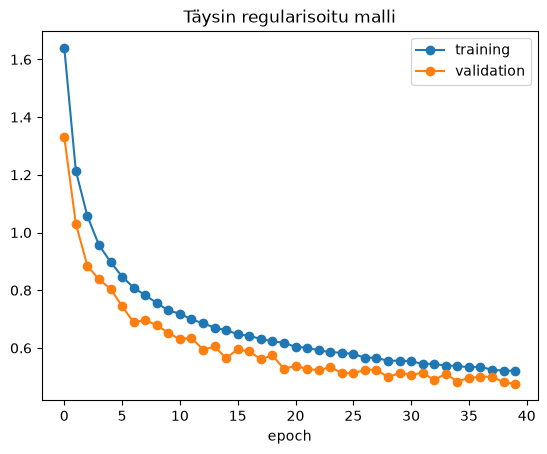

Train accuracy (viimeinen ep): 81.94%
Val accuracy (paras):          84.18%


In [53]:
def build_regularized_model(dropout_rate=0.5, translation=0.1, momentum=0.9):
    data_augmentation = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomTranslation(translation, translation),
    ])

    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        data_augmentation,

        layers.Conv2D(32, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.Conv2D(32, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),

        layers.Conv2D(64, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.Conv2D(64, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),

        layers.Flatten(),
        layers.Dropout(dropout_rate),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


print("\n Täysin regularisoitu malli: BN 0.9 + Dropout 0.5 + Aug 0.1 (40 ep, patience=6) ")
keras.utils.set_random_seed(0)

model_regularized = build_regularized_model(dropout_rate=0.5, translation=0.1, momentum=0.9)
timer_regularized = EpochTimer()
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=6, restore_best_weights=True
)

history_regularized = model_regularized.fit(
    x_train_std, y_train,
    epochs=40,
    validation_split=0.1,
    callbacks=[early_stop, timer_regularized],
    verbose=2
)

loss_reg, acc_reg = model_regularized.evaluate(x_test_std, y_test, verbose=0)
best_epoch_reg = int(np.argmin(history_regularized.history["val_loss"])) + 1

df_regularized = pd.DataFrame([{
    "Malli": "Täysin regularisoitu (BN 0.9 + Dropout 0.5 + Aug 0.1)",
    "Test accuracy": acc_reg,
    "Test loss": loss_reg,
    "Parametrit": model_regularized.count_params(),
    "Epookkeja": len(timer_regularized.epoch_times),
    "Paras epookki": best_epoch_reg,
}])
display(df_regularized.style.hide(axis="index").format({
    "Test accuracy": "{:.2%}",
    "Test loss": "{:.4f}",
    "Parametrit": "{:,}",
}))

plt.plot(history_regularized.history["loss"], marker="o", label="training")
plt.plot(history_regularized.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.title("Täysin regularisoitu malli")
plt.legend()
plt.show()

print(f"Train accuracy (viimeinen ep): {history_regularized.history['accuracy'][-1]:.2%}")
print(f"Val accuracy (paras):          {max(history_regularized.history['val_accuracy']):.2%}")

# 5. Arviointi

## 5.1 Neuronien määrä ja kerrosten määrä

### 5.1.1 Neuronimäärien ja kerrosten määrien kokeilu

Arvioidaan mallien suorituskyky testidataan ja vertaillaan niitä yhdessä dataframessa.

In [54]:

import pandas as pd

# Standardoidaan testidata koulutusdatasta lasketuilla RGB-arvoilla
x_test_std = (x_test - rgb_mean) / rgb_std

# Määritetään vertailtavat mallit ja niiden ajastimet
models = {
    "16/32 (2 kerrosta)": (
        model16_32_2layer, timer_16_32_2layer, False
    ),
    "32/64 (2 kerrosta)": (
        model32_64_2layer, timer_32_64_2layer, False
    ),
    "32/64 (RGB-standardoitu)": (
        std_models["32/64"], std_timers["32/64"], True
    ),
    "64/128 (2 kerrosta)": (
        model64_128_2layer, timer_64_128_2layer, False
    ),
    "32/32/64 (3 kerrosta)": (
        model32_32_64_3layer, timer_32_32_64_3layer, False
    ),
    "32/32/64 (RGB-standardoitu)": (
        std_models["32/32/64"], std_timers["32/32/64"], True
    ),
    "64/64/128 (3 kerrosta)": (
        model64_64_128_3layer, timer_64_64_128_3layer, False
    ),
    "32/32/64/64 (4 kerrosta)": (
        model32_32_64_64_4layer, timer_32_32_64_64_4layer, False
    ),
    "32/32/64/64 (RGB-standardoitu)": (
        std_models["32/32/64/64"], std_timers["32/32/64/64"], True
    )
}

results = []

# Arvioidaan jokainen malli testidatalla
for name, (model, timer, standardized) in models.items():

    # Valitaan oikea testidata
    test_data = x_test_std if standardized else x_test

    test_loss, test_accuracy = model.evaluate(
        test_data, y_test, verbose=0
    )

    results.append({
        "Malli": name,
        "Test loss": test_loss,
        "Test accuracy (%)": test_accuracy * 100,
        "Parametrit": model.count_params(),
        "Kokonaissuoritusaika (s)": sum(timer.epoch_times)
    })

# Muodostetaan DataFrame
df_evaluation = pd.DataFrame(results)

# Näytetään tulokset ilman indeksiä
display(
    df_evaluation.style
    .hide(axis="index")
    .format({
        "Test loss": "{:.4f}",
        "Test accuracy (%)": "{:.2f}",
        "Parametrit": "{:,}",
        "Kokonaissuoritusaika (s)": "{:.2f}"
    })
)


2026-10-28 15:00:56.713231: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-28 15:01:01.926317: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


Malli,Test loss,Test accuracy (%),Parametrit,Kokonaissuoritusaika (s)
16/32 (2 kerrosta),0.9379,68.83,"25,578",78.10
32/64 (2 kerrosta),0.9052,69.12,"60,362",50.59
32/64 (RGB-standardoitu),0.9118,68.94,"60,362",32.41
64/128 (2 kerrosta),0.9199,69.80,"157,578",45.36
32/32/64 (3 kerrosta),0.8603,70.44,"69,610",41.56
32/32/64 (RGB-standardoitu),0.8359,72.28,"69,610",35.62
64/64/128 (3 kerrosta),0.8665,70.23,"194,506",31.97
32/32/64/64 (4 kerrosta),0.8173,72.30,"106,538",44.25
32/32/64/64 (RGB-standardoitu),0.8545,73.12,"106,538",43.43


### 5.1.2 Johtopäätökset

Suodattimien lisääminen ei automaattisesti parantanut mallien tarkkuutta. Kerroksien lisääminen selvästi kasvatti mallien testitarkkuutta 2 kerroksisesta `32/64`-mallin 69,12%:sta nelikerroksiseen 72,30%:n. Paras testitarkkuus **72,3 %** ja pienin test loss **0,8173** saavutettiin nelikerroksisella `32/32/64/64`-mallilla. Standartoidut RBG-arvot nostivat tarkkuuden **73,12 %**, mutta nosti test lossin **0,8545**. Lisä hyperparametrien muokkaus kannattaa toteuttaa rinnakkain RGB standardoinnin kanssa.

Verrattuna kaksikerroksiseen `32/64`-malliin nelikerroksisen RGB standardoinnun tarkkuus parani **4,00 prosenttiyksikköä**. Lisäksi koulutusaika laski kierrosmäärän laskiessa kaksikerroksisen 6:sta nelikerroksisen 4:n.

## 5.2 Luokittelutulokset

Ennustetaan ja visualisoidaan mallin lopputuloksia. Luodaan 60 kuvan ennustus ja katsotaan onko mahdollisia trendejä oikea-ennuste välillä.

### 5.2.1 Baseline 32/32/64/64-malli ei RGB standardoitu

#### 5.2.1.1 Baseline 32/32/64/64-malli ennusteet kuvittain

Pohjamalli, missä ei ole muokattu kuin neuronien ja kerrosten määriä.

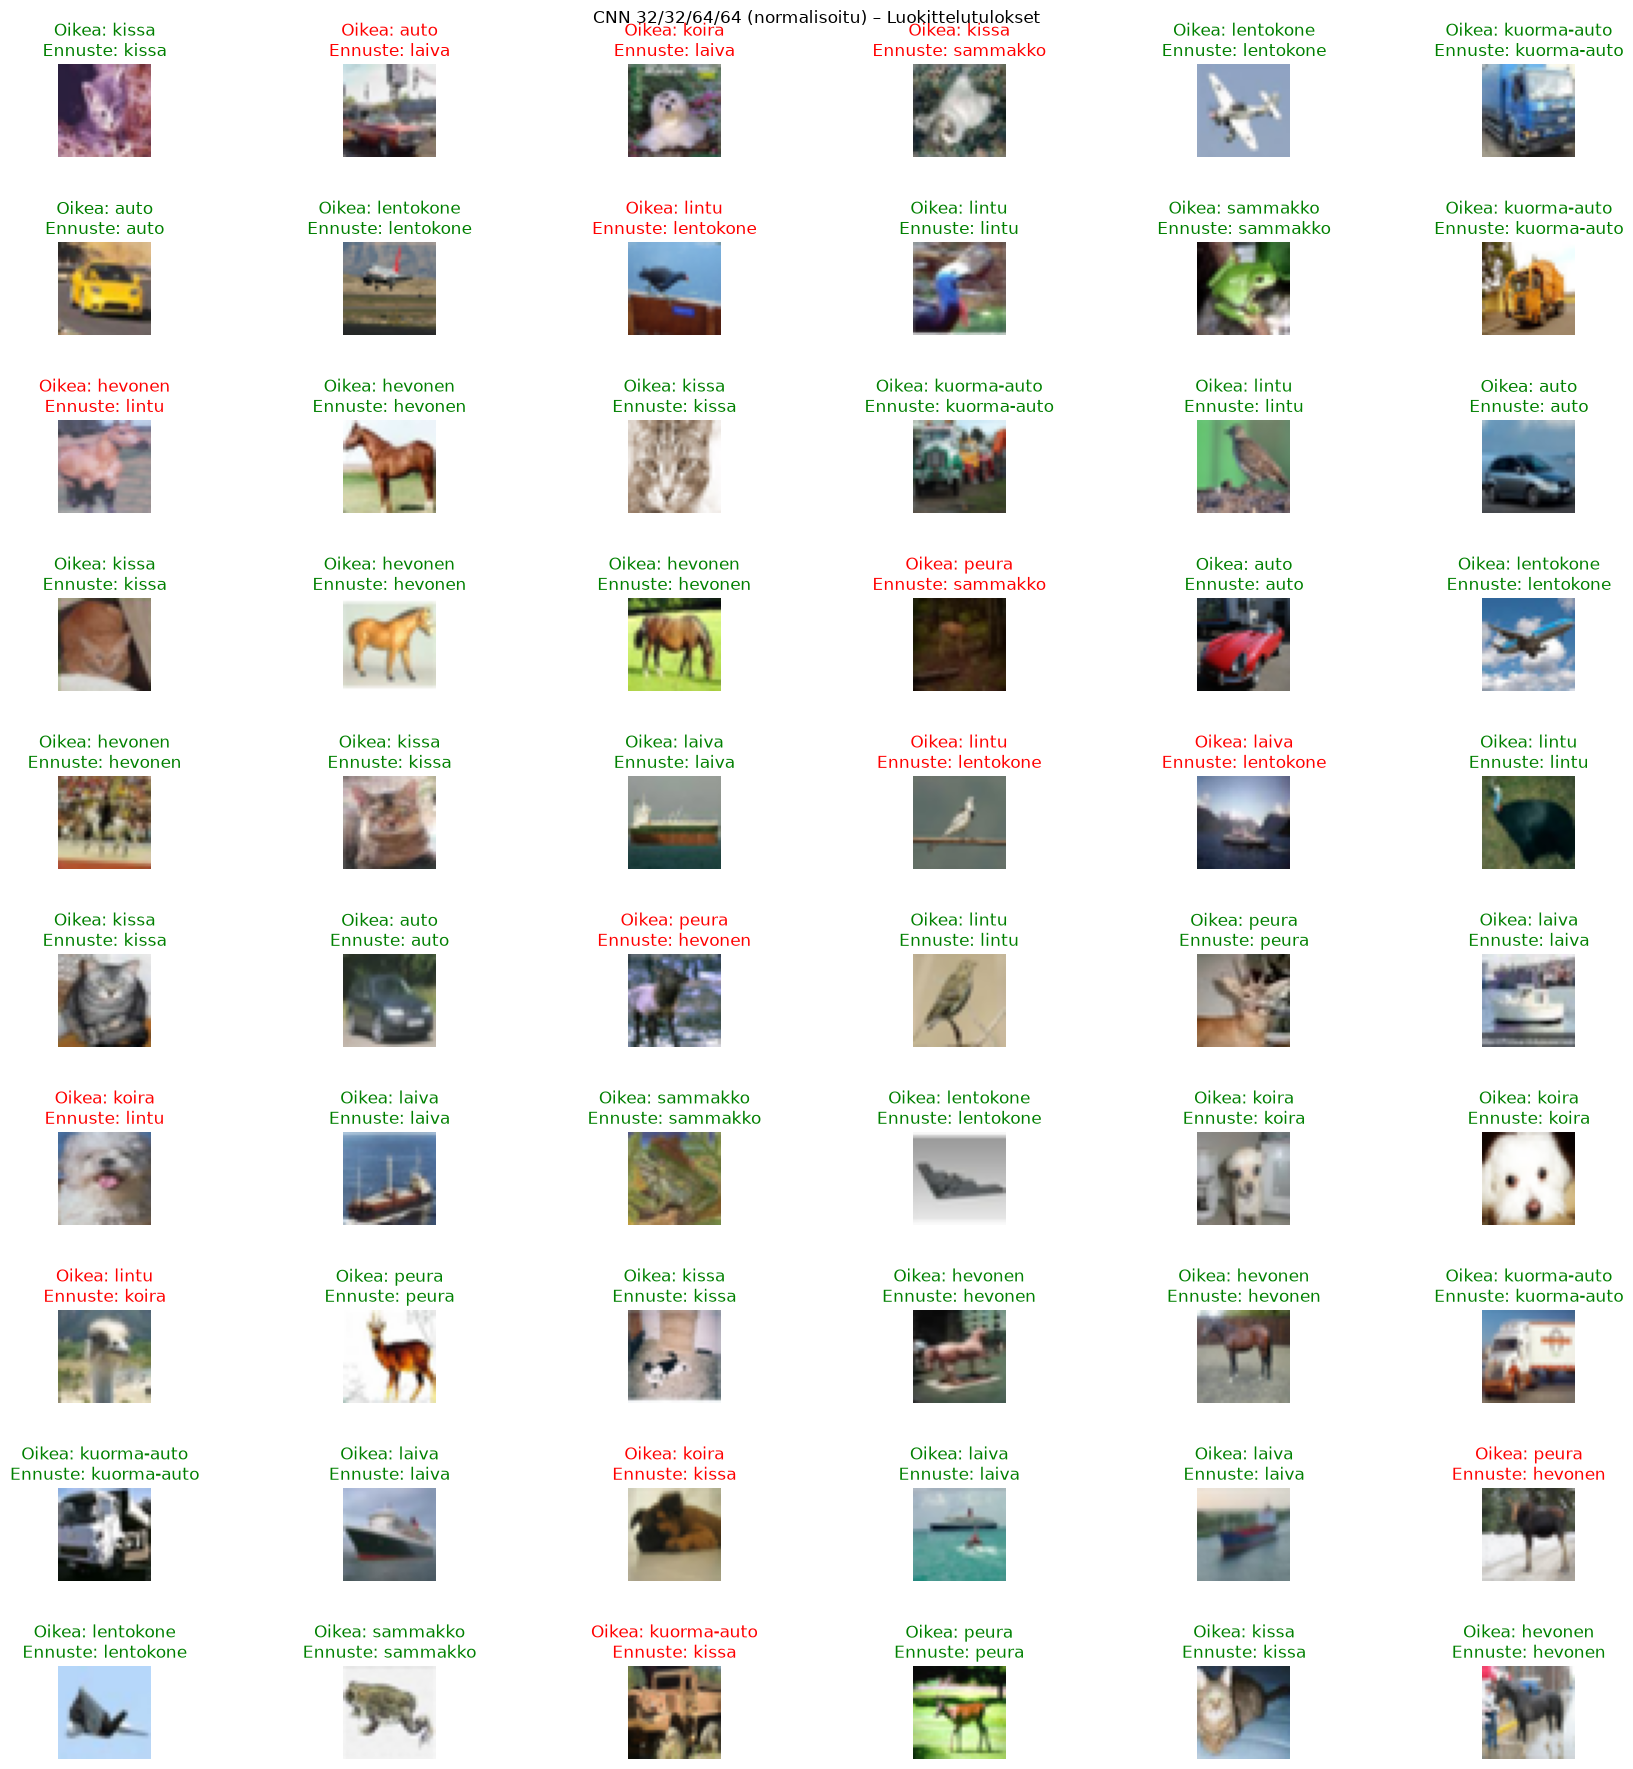

In [55]:
# Valitaan alkuperäinen CNN-malli ilman RGB-standardointia
model_normal = model32_32_64_64_4layer

# Valitaan samat validointikuvat kuin koulutuksessa
x_val = x_train[-5000:]
y_val = y_train[-5000:].ravel()

# Valitaan 60 satunnaista kuvaa toistettavasti
rng = np.random.default_rng(0)
indices = rng.choice(len(x_val), size=60, replace=False)

# Ennustetaan normalisoiduilla kuvilla
predictions = model_normal.predict(
    x_val[indices], verbose=0
)

predicted_classes = np.argmax(predictions, axis=1)

fig, axes = plt.subplots(10, 6, figsize=(18, 18))

for i, ax in enumerate(axes.flat):
    true_class = int(y_val[indices[i]])
    predicted_class = int(predicted_classes[i])

    ax.imshow(x_val[indices[i]])

    correct = true_class == predicted_class
    color = "green" if correct else "red"

    ax.set_title(
        f"Oikea: {class_names[true_class]}\n"
        f"Ennuste: {class_names[predicted_class]}",
        color=color
    )
    ax.axis("off")

plt.suptitle("CNN 32/32/64/64 (normalisoitu) – Luokittelutulokset")
plt.tight_layout(h_pad=3.0, w_pad=1.5)
plt.show()


### 5.2.1.2 Johtopäätökset

Normalisoidun CNN-mallin 60 kuvan otoksesta 46 luokiteltiin oikein ja 14 väärin, jolloin otoksen luokittelutarkkuus oli 76,7 %. Toistuvia virheitä havaittiin erityisesti linnun ennustamisessa lentokoneeksi ja peuran ennustamisessa hevoseksi. Molemmat virheet esiintyivät kahdesti.

Visuaalisesti samankaltaiset piirteet, kuten peuran ja hevosen ruumiinrakenne sekä linnun ja lentokoneen muodot, saattavat selittää osan virheistä. Kaikkia virheitä ei kuitenkaan voida selittää samankaltaisuudella, sillä esimerkiksi koira luokiteltiin laivaksi ja kuorma-auto kissaksi.

### 5.2.2 Baseline 32/32/64/64-malli RGB standardoitu

#### 5.2.2.1 Baseline 32/32/64/64-malli ennusteet kuvittain

Pohjamalli, missä ei ole muokattu kuin neuronien ja kerrosten määriä.

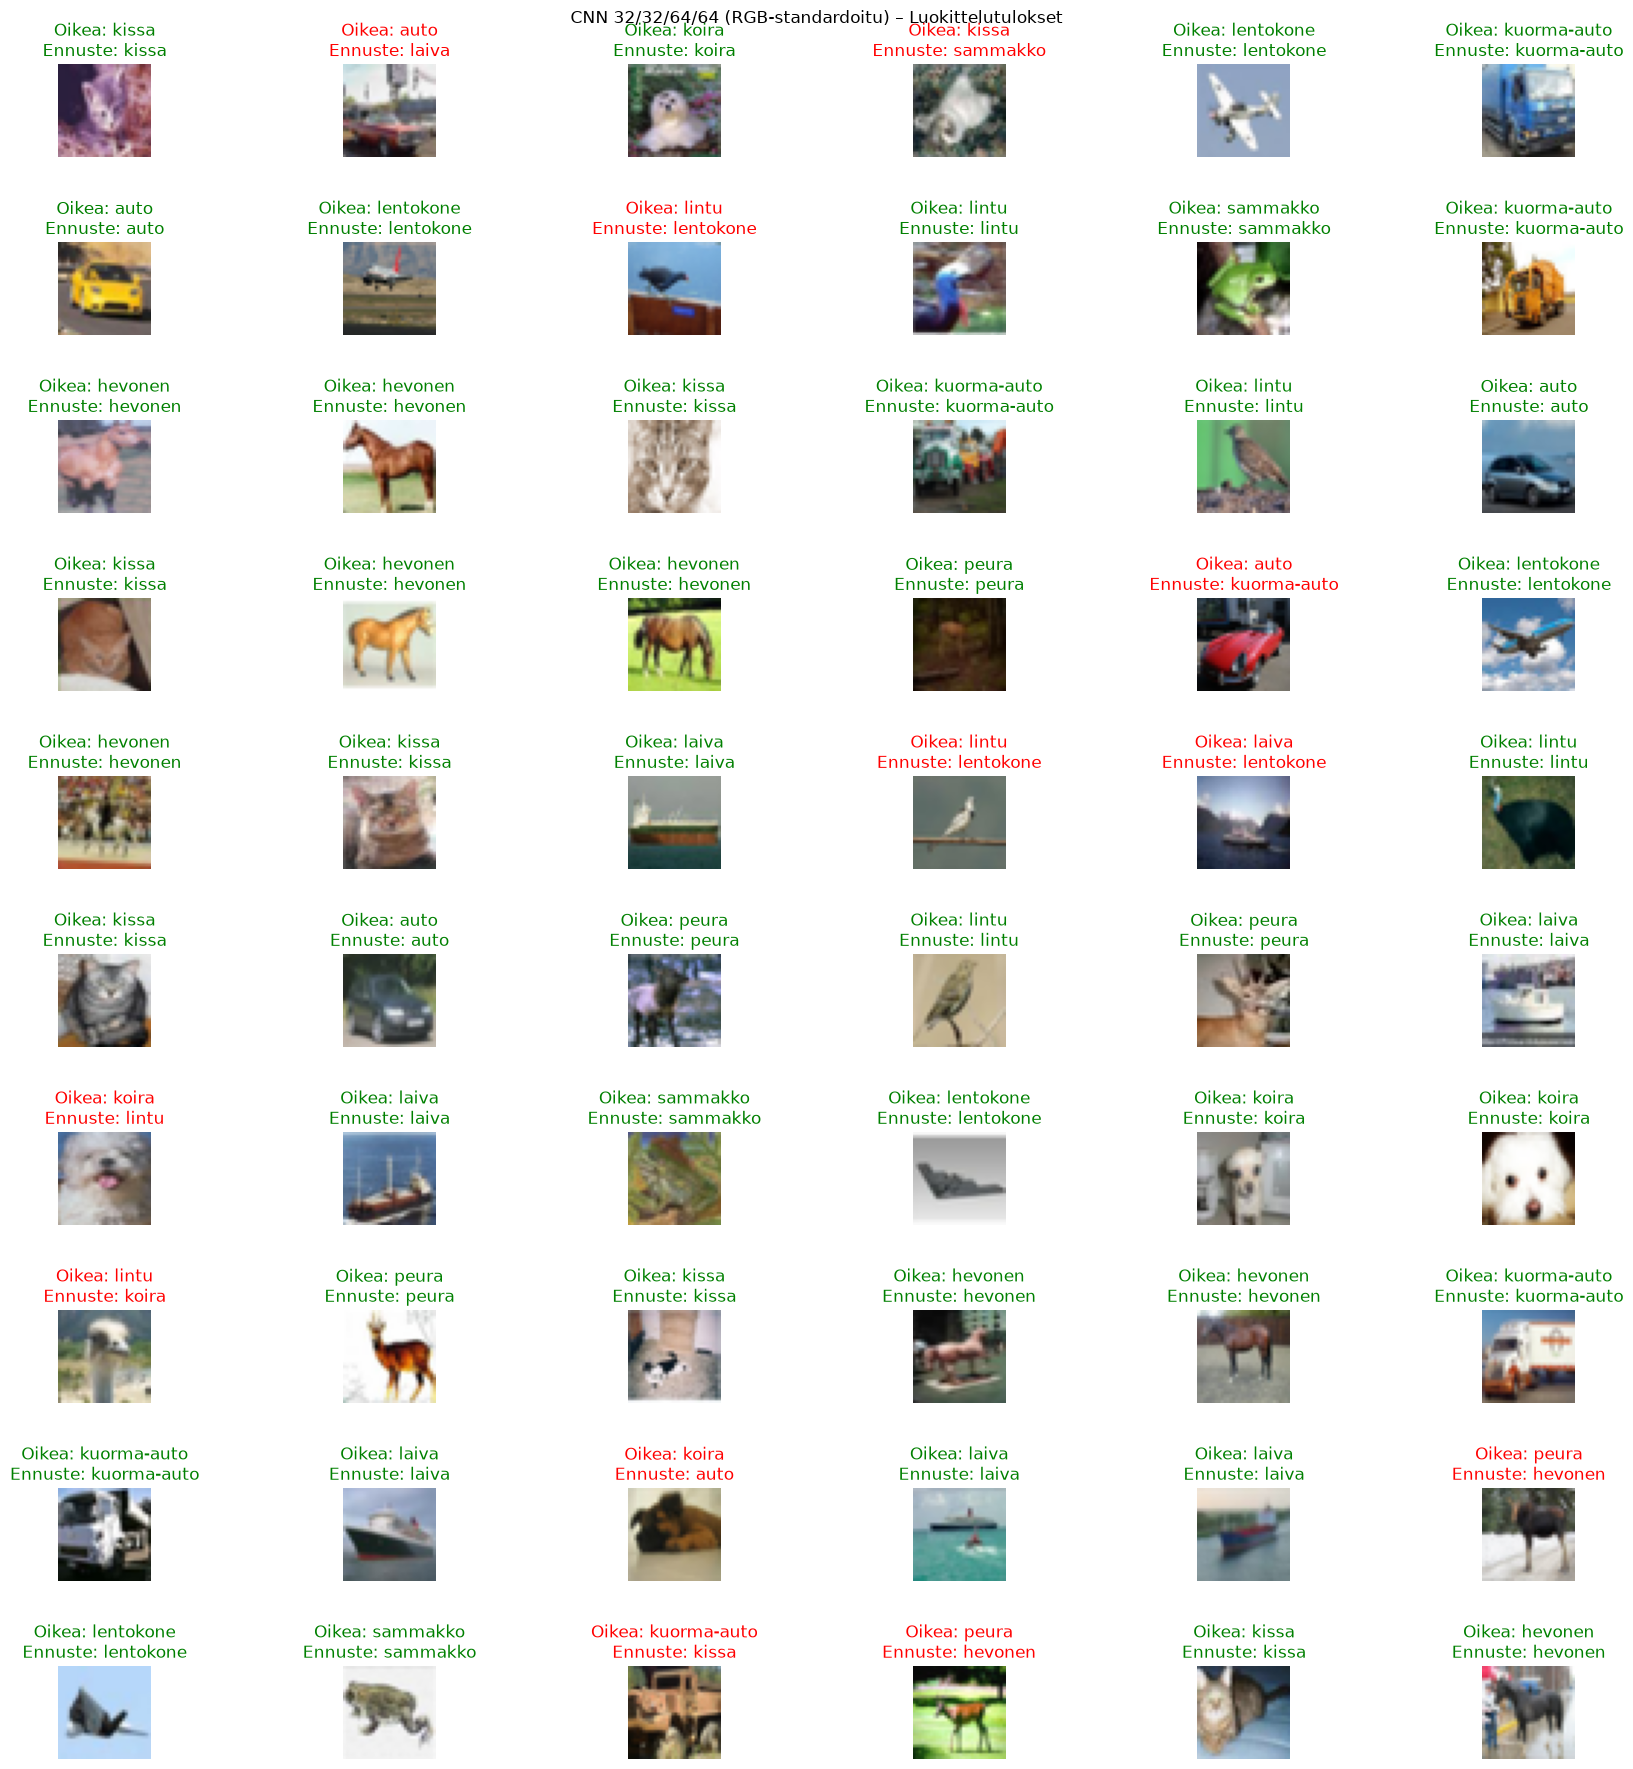

In [56]:
# Valitaan RGB-standardoitu CNN-malli
model_rgb = std_models["32/32/64/64"]

# Valitaan samat validointikuvat kuin koulutuksessa
x_val = x_train[-5000:]
x_val_std = x_train_std[-5000:]
y_val = y_train[-5000:].ravel()

# Valitaan 60 satunnaista kuvaa toistettavasti
rng = np.random.default_rng(0)
indices = rng.choice(len(x_val), size=60, replace=False)

# Ennustetaan standardoiduilla kuvilla
predictions = model_rgb.predict(
    x_val_std[indices], verbose=0
)

predicted_classes = np.argmax(predictions, axis=1)

fig, axes = plt.subplots(10, 6, figsize=(18, 18))

for i, ax in enumerate(axes.flat):
    true_class = int(y_val[indices[i]])
    predicted_class = int(predicted_classes[i])

    # Näytetään alkuperäinen normalisoitu RGB-kuva
    ax.imshow(x_val[indices[i]])

    correct = true_class == predicted_class
    color = "green" if correct else "red"

    ax.set_title(
        f"Oikea: {class_names[true_class]}\n"
        f"Ennuste: {class_names[predicted_class]}",
        color=color
    )
    ax.axis("off")

plt.suptitle("CNN 32/32/64/64 (RGB-standardoitu) – Luokittelutulokset")
plt.tight_layout(h_pad=3.0, w_pad=1.5)
plt.show()


#### 5.2.2.2 Johtopäätökset

RGB-standardoidun CNN-mallin 60 kuvan otoksesta 48 luokiteltiin oikein ja 12 väärin, jolloin otoksen luokittelutarkkuus oli 80 %. Toistuvia virheitä havaittiin erityisesti linnun ennustamisessa lentokoneeksi ja peuran ennustamisessa hevoseksi. Molemmat virheet esiintyivät kahdesti.

Visuaalisesti samankaltaiset piirteet, kuten peuran ja hevosen ruumiinrakenne sekä linnun ja lentokoneen muodot, saattavat selittää osan virheistä. Kaikkia virheitä ei kuitenkaan voida selittää samankaltaisuudella, sillä esimerkiksi kuorma-auto luokiteltiin kissaksi ja koira autoksi.

### 5.2.3 Johtopäätökset RGB-standardointi vs. normalisointi

Normalisoitu CNN-malli luokitteli 60 kuvasta 46 oikein (76,7 %), kun taas RGB-standardoitu malli luokitteli 48 oikein (80 %). RGB-standardointi paransi tämän otoksen luokittelutarkkuutta 3,3 prosenttiyksikköä.

Molemmissa malleissa havaittiin samankaltaisia virheitä, erityisesti linnun ennustamisessa lentokoneeksi ja peuran ennustamisessa hevoseksi. Molemmat virheet esiintyivät kummallakin mallilla kahdesti. Mallien yksittäiset ennusteet kuitenkin erosivat toisistaan, joten RGB-standardointi paransi joidenkin kuvien luokittelua mutta heikensi toisten.

Tulokset viittaavat siihen, että RGB-standardointi voi parantaa mallin luokittelutarkkuutta, mutta 60 kuvan otos on liian pieni luotettavien yleisten johtopäätösten tekemiseen. Tämän vuoksi standardoinnin vaikutusta kannattaa arvioida ensisijaisesti koko validointiaineiston tulosten perusteella.

## 5.3 Softmax-todennököisyys jakaumat

Tarkastellaan, miten ennustuksen äänet jakautuvat softmax todennäköisyys jakaumalla.

### 5.3.1.1. Baseline 32/32/64/64-malli ei RGB-standardoitu

2026-10-28 15:01:13.119372: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


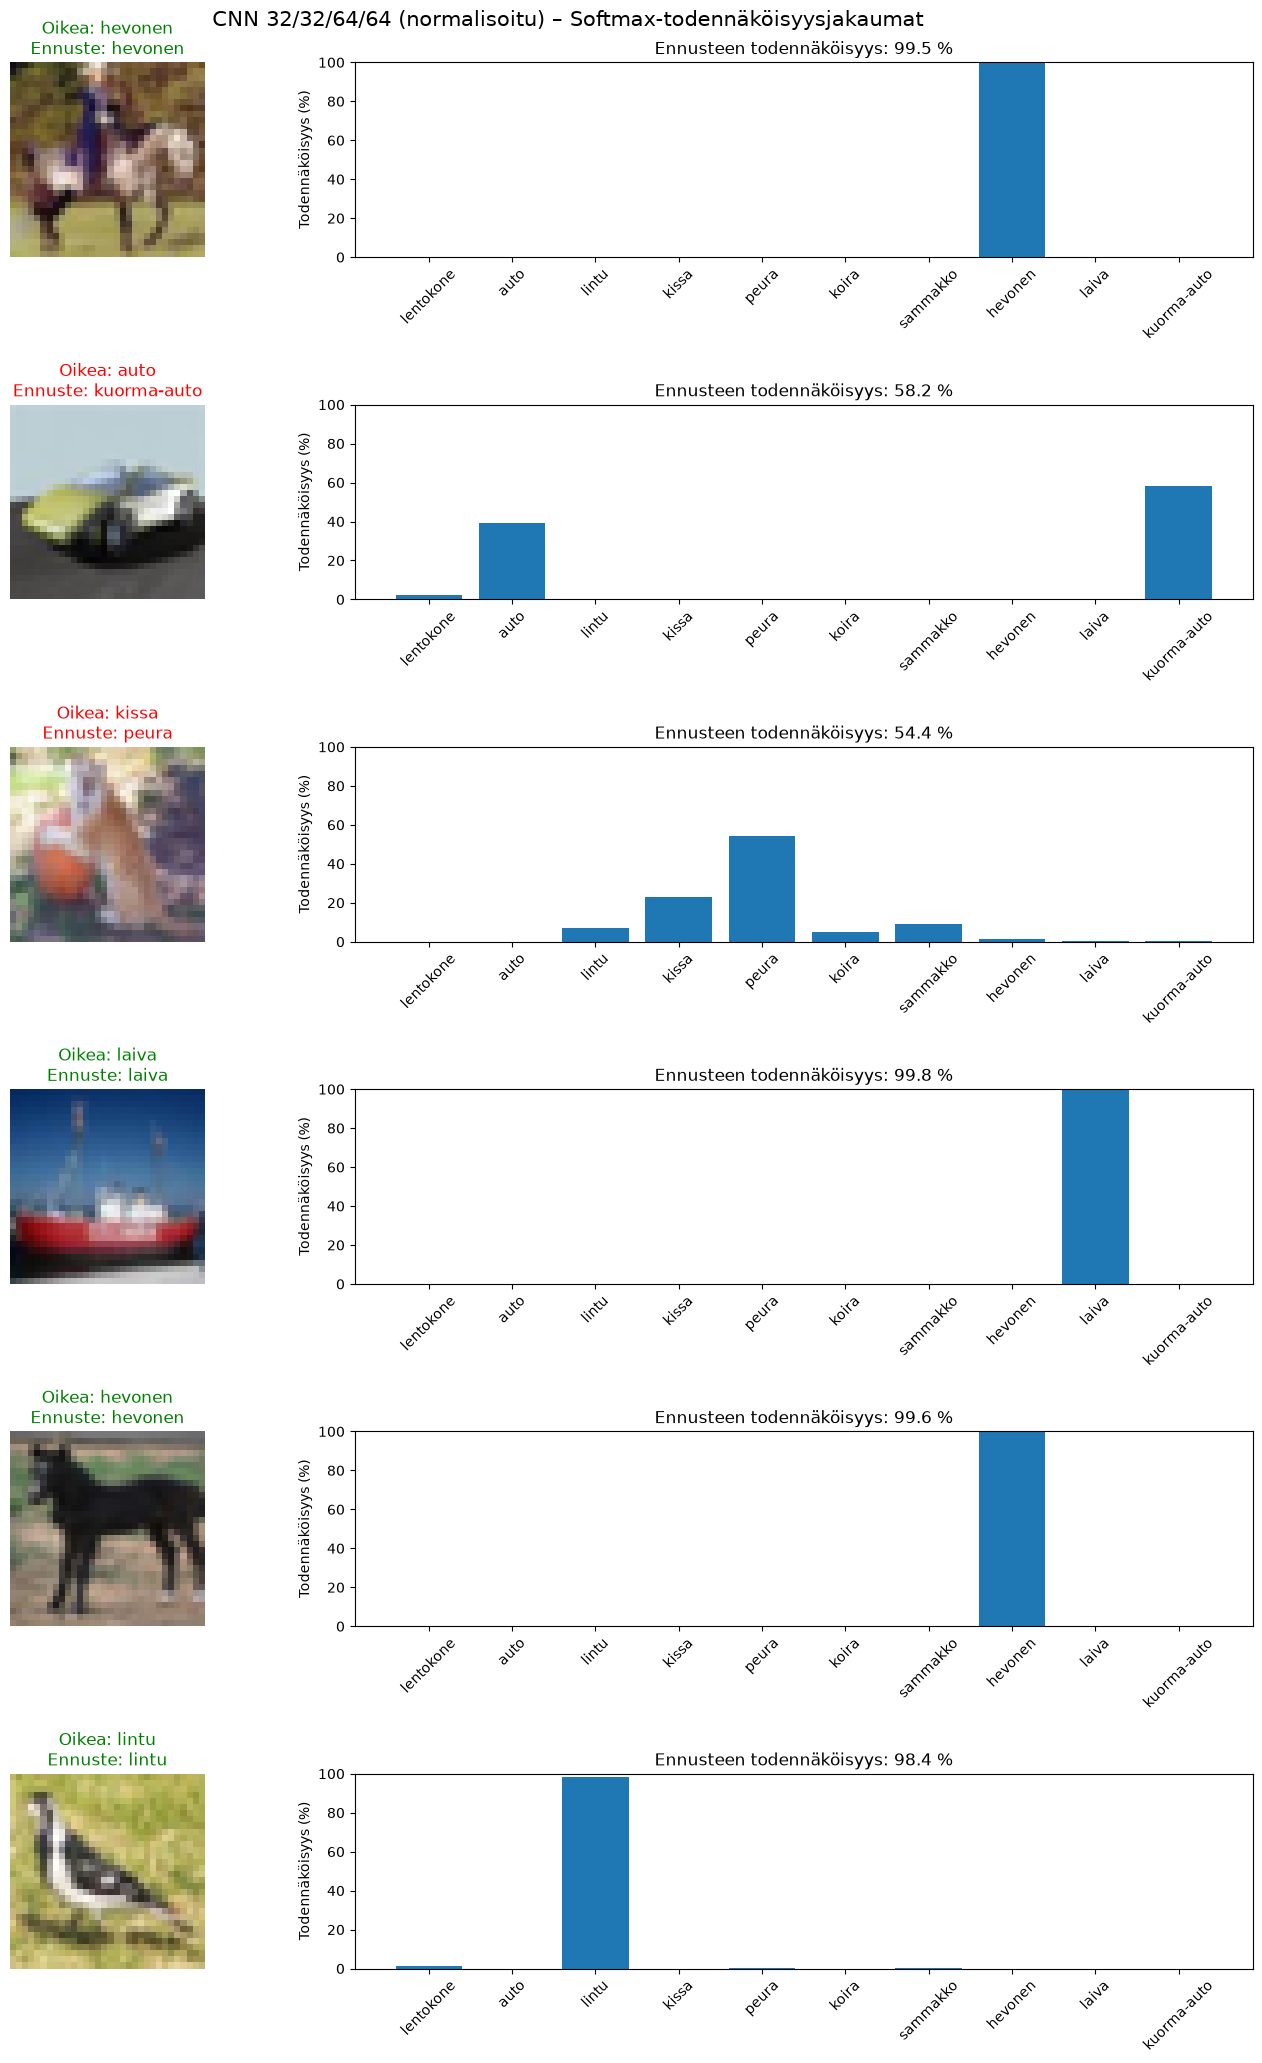

In [57]:
# Valitaan alkuperäinen CNN-malli ilman RGB-standardointia
model_normal = model32_32_64_64_4layer

# Valitaan samat validointikuvat
x_val = x_train[-5000:]
y_val = y_train[-5000:].ravel()

# Kuvien määrä
num_images = 6

# Valitaan satunnaiset kuvat kiinteällä siemenellä
rng = np.random.default_rng(0)
selected_indices = rng.choice(
    len(x_val), size=num_images, replace=False
)

# Ennustetaan normalisoitujen kuvien todennäköisyydet
probabilities = model_normal.predict(
    x_val[selected_indices], verbose=0
)

# Luodaan kuvaajat
fig, axes = plt.subplots(
    num_images, 2,
    figsize=(14, num_images * 3.5),
    gridspec_kw={"width_ratios": [1, 2]}
)

for i in range(num_images):
    image = x_val[selected_indices[i]]
    true_class = int(y_val[selected_indices[i]])
    predicted_class = np.argmax(probabilities[i])

    correct = true_class == predicted_class
    color = "green" if correct else "red"

    # Alkuperäinen RGB-kuva
    axes[i, 0].imshow(image)
    axes[i, 0].set_title(
        f"Oikea: {class_names[true_class]}\n"
        f"Ennuste: {class_names[predicted_class]}",
        color=color
    )
    axes[i, 0].axis("off")

    # Softmax-jakauma
    axes[i, 1].bar(
        class_names,
        probabilities[i] * 100
    )

    axes[i, 1].set_title(
        f"Ennusteen todennäköisyys: "
        f"{probabilities[i][predicted_class] * 100:.1f} %"
    )
    axes[i, 1].set_ylabel("Todennäköisyys (%)")
    axes[i, 1].set_ylim(0, 100)
    axes[i, 1].tick_params(axis="x", rotation=45)

plt.suptitle(
    "CNN 32/32/64/64 (normalisoitu) – Softmax-todennäköisyysjakaumat",
    fontsize=15
)
plt.tight_layout(h_pad=3.0)
plt.show()


### 5.3.1.2. Johtopäätökset

Normalisoitu CNN-malli luokitteli kuudesta kuvasta neljä oikein ja kaksi väärin. Oikein luokiteltujen kuvien suurimmat softmax-todennäköisyydet olivat 98,4–99,8 %. Virheellisissä ennusteissa auto luokiteltiin kuorma-autoksi (58,2 %) ja kissa peuraksi (54,4 %).

Väärin luokitelluissa kuvissa todennäköisyydet jakautuivat useammalle luokalle. Sekä auto että kissa saivat myös huomattavan osuuden todennäköisyysjakaumasta. Visuaalisesti samankaltaiset piirteet saattavat selittää osan virheistä, mutta niiden vaikutusta ei voida varmistaa näiden kuvien perusteella.

Tulokset osoittavat, että malli voi antaa virheelliselle ennusteelle suurimman softmax-arvon, vaikka oikeakin luokka saa huomattavan osuuden.

### 5.3.2.1. Baseline 32/32/64/64-malli RGB-standardoitu

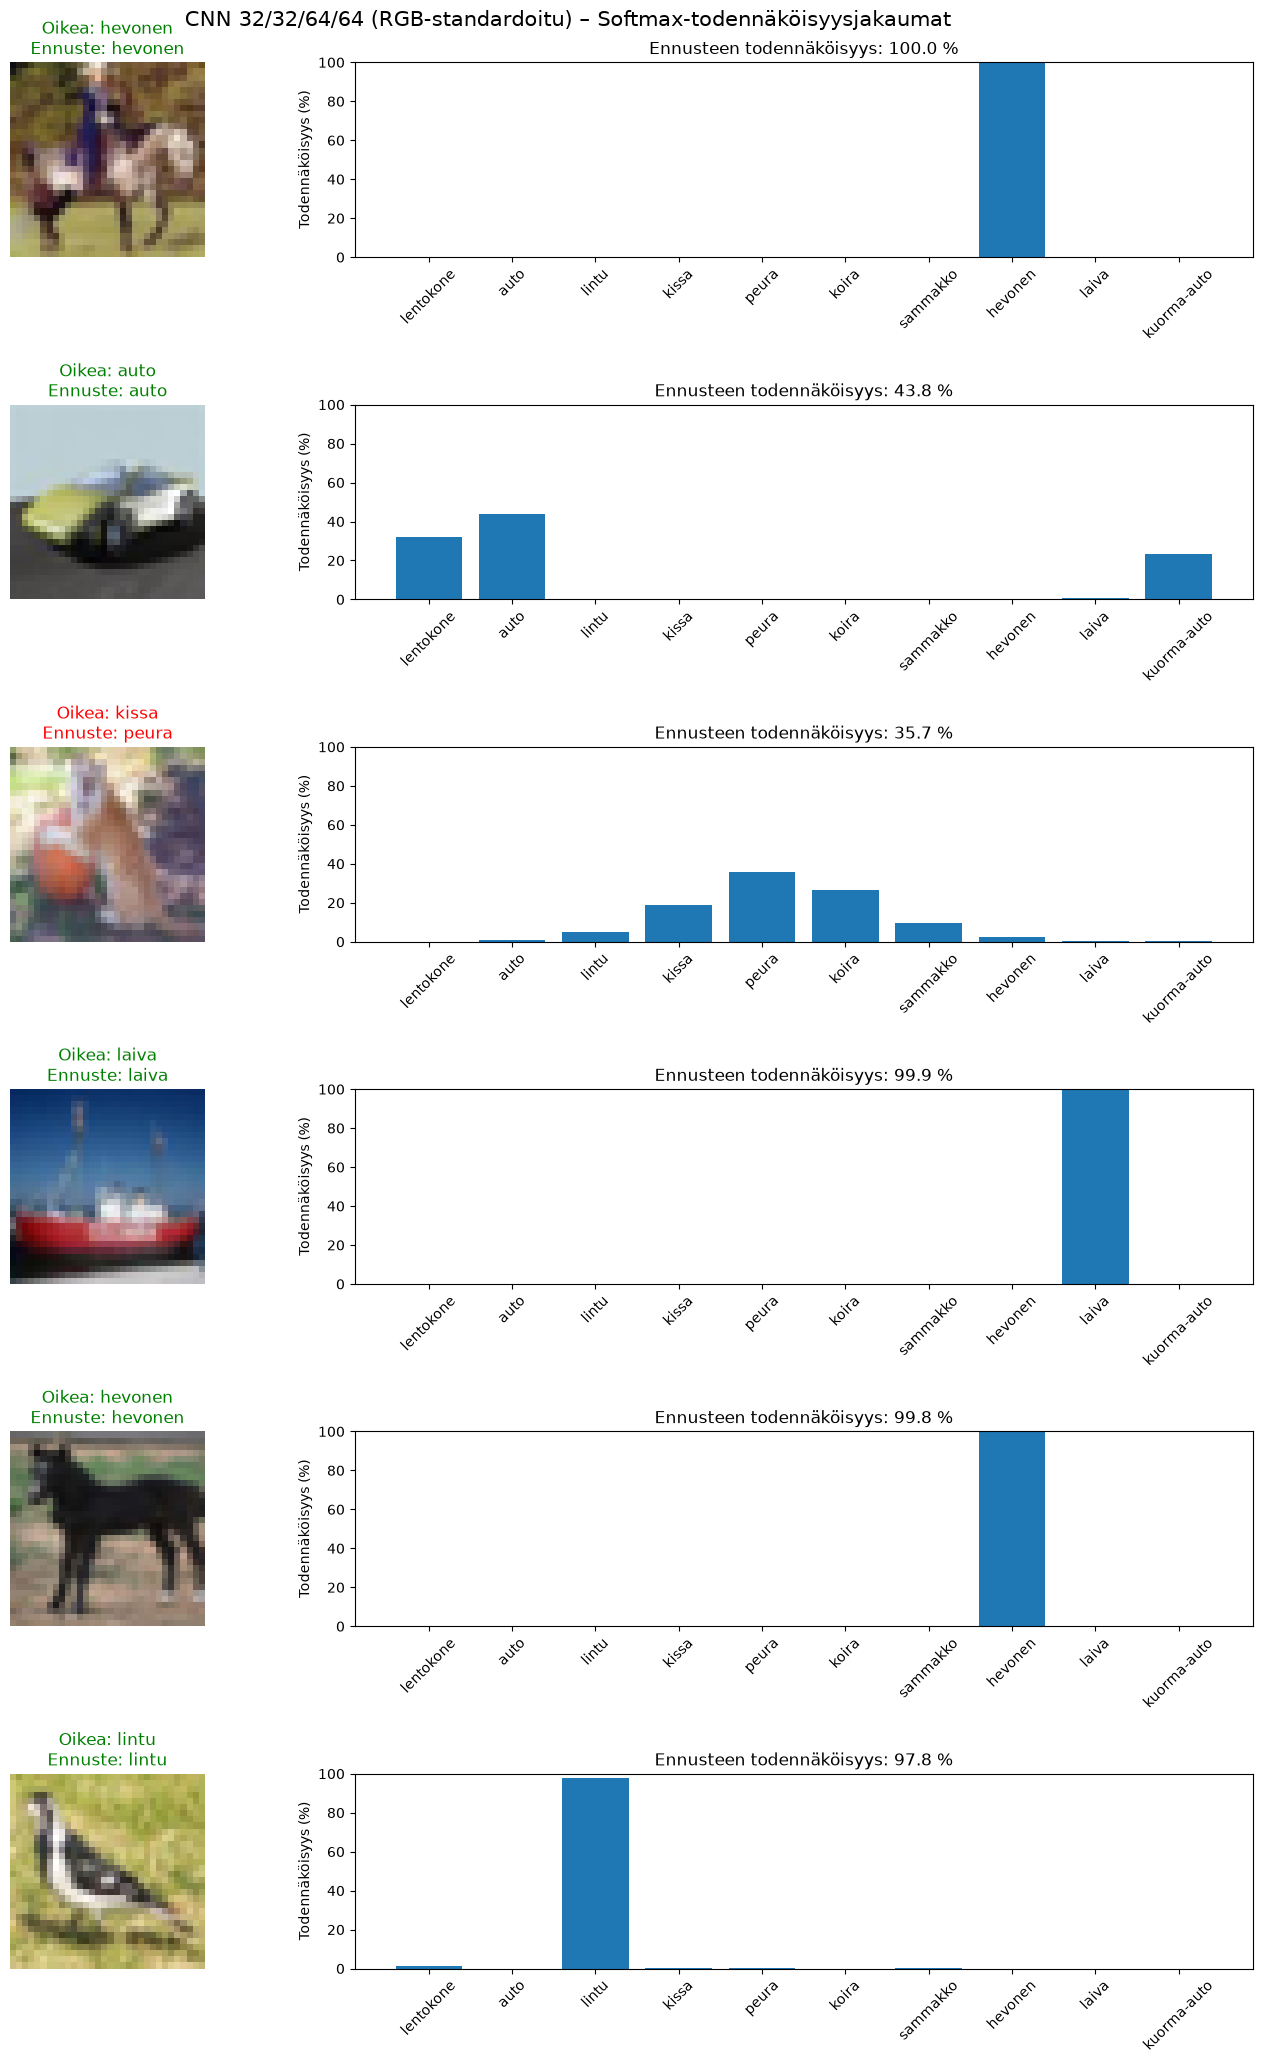

In [58]:
# Kuvien määrä
num_images = 6

# Valitaan satunnaiset kuvat kiinteällä siemenellä
rng = np.random.default_rng(0)
selected_indices = rng.choice(
    len(x_val), size=num_images, replace=False
)

# Ennustetaan standardoitujen kuvien todennäköisyydet
probabilities = model_rgb.predict(
    x_val_std[selected_indices], verbose=0
)

# Luodaan kuvaajat
fig, axes = plt.subplots(
    num_images, 2,
    figsize=(14, num_images * 3.5),
    gridspec_kw={"width_ratios": [1, 2]}
)

for i in range(num_images):
    image = x_val[selected_indices[i]]
    true_class = int(y_val[selected_indices[i]])
    predicted_class = np.argmax(probabilities[i])

    correct = true_class == predicted_class
    color = "green" if correct else "red"

    # Alkuperäinen RGB-kuva
    axes[i, 0].imshow(image)
    axes[i, 0].set_title(
        f"Oikea: {class_names[true_class]}\n"
        f"Ennuste: {class_names[predicted_class]}",
        color=color
    )
    axes[i, 0].axis("off")

    # Softmax-jakauma
    axes[i, 1].bar(
        class_names,
        probabilities[i] * 100
    )

    axes[i, 1].set_title(
        f"Ennusteen todennäköisyys: "
        f"{probabilities[i][predicted_class] * 100:.1f} %"
    )
    axes[i, 1].set_ylabel("Todennäköisyys (%)")
    axes[i, 1].set_ylim(0, 100)
    axes[i, 1].tick_params(axis="x", rotation=45)

plt.suptitle(
    "CNN 32/32/64/64 (RGB-standardoitu) – Softmax-todennäköisyysjakaumat",
    fontsize=15
)
plt.tight_layout(h_pad=3.0)
plt.show()


### 5.3.2.2. Johtopäätökset

RGB-standardoitu CNN-malli luokitteli kuudesta kuvasta viisi oikein ja yhden väärin. Neljän oikein luokitellun kuvan suurimmat softmax-todennäköisyydet olivat 97,8–100,0 %. Auton kohdalla oikean ennusteen todennäköisyys oli kuitenkin vain 43,8 %.

Auton todennäköisyydet jakautuivat useammalle luokalle, erityisesti auton, lentokoneen ja kuorma-auton välille. Virheellisessä ennusteessa kissa luokiteltiin peuraksi (35,7 %). Myös koira ja kissa saivat huomattavia osuuksia todennäköisyysjakaumasta. Visuaalisesti samankaltaiset piirteet saattavat selittää osan sekoittumisesta.

Tulokset osoittavat, että malli voi luokitella kuvan oikein myös pienemmällä softmax-arvolla. Suurin softmax-arvo ei kuitenkaan takaa oikeaa ennustetta.

## 5.3.2 Johtopäätökset

Normalisoitu CNN-malli luokitteli kuudesta kuvasta neljä oikein ja RGB-standardoitu viisi. Suurimmat softmax-todennäköisyydet olivat molemmilla malleilla useimmissa oikein luokitelluissa kuvissa lähes 100 %.

RGB-standardointi paransi auton luokittelua. Normalisoitu malli ennusti auton virheellisesti kuorma-autoksi (58,2 %), kun taas RGB-standardoitu malli tunnisti auton oikein (43,8 %). Kissa luokiteltiin molemmilla malleilla virheellisesti peuraksi, mutta RGB-standardoinnilla peuran softmax-arvo pieneni 54,4 %:sta 35,7 %:iin.

Tulokset osoittavat, että suurempi softmax-arvo ei välttämättä tarkoita oikeaa ennustetta. RGB-standardointi paransi tässä otoksessa luokittelua, mutta kuuden kuvan perusteella ei voida tehdä yleisiä johtopäätöksiä sen vaikutuksesta mallin suorituskykyyn.

## 5.4 Regularisointikokeilujen arviointi


### 5.4.1 Johtopäätökset: Dropout

Dropout-sweepin paras tulos saatiin arvolla **0.5**. Sen test accuracy oli **76.56 %**, test loss **0.6960** ja paras epookki **14**.

### 5.4.2 Johtopäätökset: Data Augmentaatio

Augmentaatio-sweepin paras tulos saatiin translation-arvolla **0.1**. Sen test accuracy oli **78.98 %**, test loss **0.6377**

### 5.4.3 Johtopäätökset: BatchNorm

BatchNorm-sweepin paras tulos saatiin momentum-arvolla **0.9**. Sen test accuracy oli **74.60 %**, test loss **0.7722** ja paras epookki **5**.

### 5.4.4 Regularisoidun mallin tulokset

Yhdistelmämalli saavutti **83.00 % test accuracyn** (loss 0.5136). Paras epoch 
oli **32** ja koulutus kesti 38 epookkia – noin 10× baseline. Val accuracy 
(84.84 %) ylitti train accuracyn (82.27 %), koska dropout ja augmentaatio 
vaikuttavat vain treenaukseen. Käytännössä ylisovittamista ei siis enää ole: 
baseline-mallin −10 pp train/val-ero on kääntynyt +2.57 pp:hen.

Huomionarvoista: **suurin osa hyödystä tuli jo Aug 0.1:stä yksin** (78.98 %). 
BN ja dropout toivat siihen päälle enää ~4 pp, mutta moninkertaistivat 
koulutusajan. Jos laskentaresurssit olisivat rajalliset, pelkkä augmentaatio 
olisi parempi valinta.

### 5.4.5 Väärin luokiteltujen kuvien tarkastelu

Kuvat havainnollistavat mallin virheellisiä luokitteluja. Tarkastelu paljastaa, mitkä luokat tuottavat mallille eniten haasteita ja miksi.

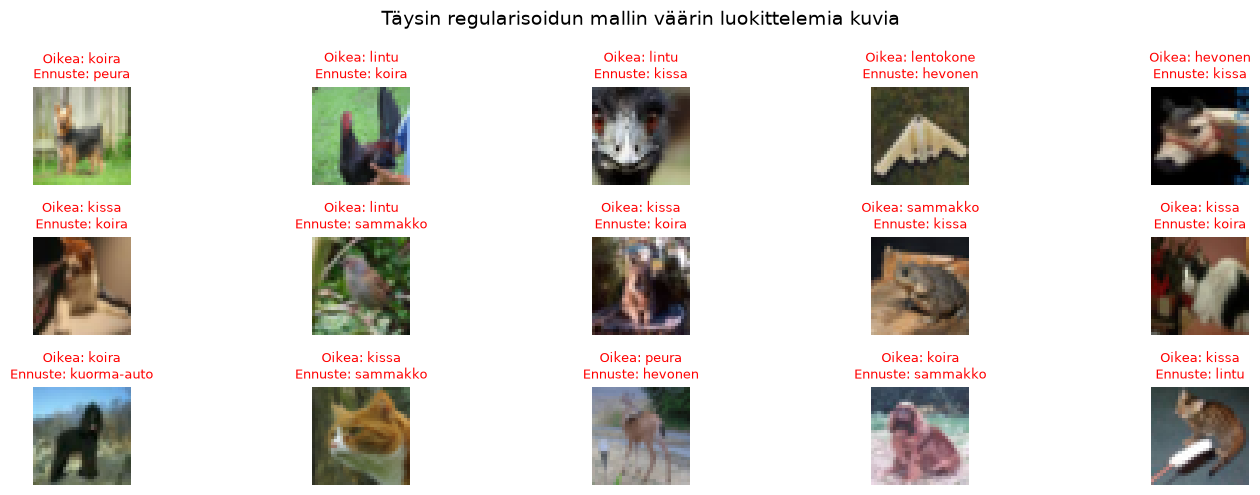

In [59]:
y_pred_reg = model_regularized.predict(x_test_std, verbose=0)
y_pred_classes_reg = np.argmax(y_pred_reg, axis=1)
y_true = y_test.flatten()

wrong_indices_reg = np.where(y_pred_classes_reg != y_true)[0]

plt.figure(figsize=(15, 5))
for i, idx in enumerate(wrong_indices_reg[:15]):
    plt.subplot(3, 5, i+1)
    plt.imshow(x_test[idx])
    plt.title(f"Oikea: {class_names[y_true[idx]]}\nEnnuste: {class_names[y_pred_classes_reg[idx]]}", fontsize=9, color="red")
    plt.axis("off")
plt.suptitle("Täysin regularisoidun mallin väärin luokittelemia kuvia", fontsize=14)
plt.tight_layout()
plt.show()

### 5.4.6 Accuracy learning curve

Accuracy learning curve kuvaa luokittelutarkkuuden kehitystä koulutuksen aikana. Harjoitus- ja validointikäyrien välinen etäisyys havainnollistaa mallin kykyä yleistää oppimansa uuteen dataan.

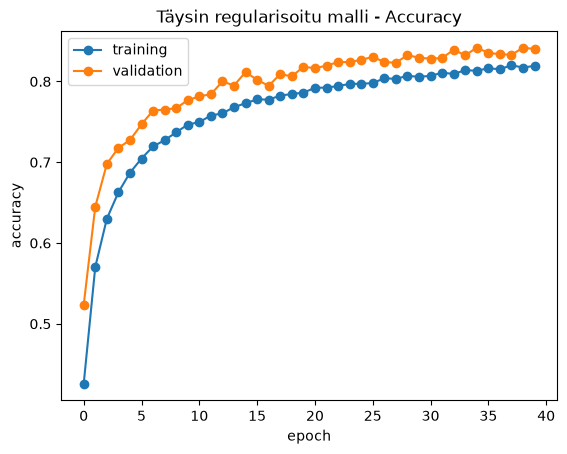

In [60]:
plt.plot(history_regularized.history["accuracy"], marker="o", label="training")
plt.plot(history_regularized.history["val_accuracy"], marker="o", label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("Täysin regularisoitu malli - Accuracy")
plt.legend()
plt.show()

#### 5.4.6.1 Accuracy learning curve

Train- ja val-käyrät kulkevat lähes käsi kädessä koko koulutuksen ajan, eli 
malli ei ylisovita. Baseline-mallilla val-accuracy kääntyisi laskuun jo 
neljännen epookin jälkeen.

### 5.4.7 Yhteenveto kaikista kokeista

**Järjestetty test accuracyn mukaan (paras ensin):**

| Malli | Test acc | Test loss | Δ baseline | Paras epoch | Epookkeja | Parametrit | Overfitting (train − val) |
|-------|----------|-----------|-----------|-------------|-----------|-----------|---------------------------|
| Täysin regularisoitu (BN 0.9 + Drop 0.5 + Aug 0.1) | 83.00 % | 0.5136 | +11.23 pp | 32 | 38 | 107,306 | −2.57 pp |
| Aug 0.1 | 78.98 % | 0.6377 | +7.21 pp | 20 | 20 | 106,538 | −0.50 pp |
| Dropout 0.5 | 76.56 % | 0.6960 | +4.79 pp | 14 | 17 | 106,538 | +3.22 pp |
| Dropout 0.3 | 75.22 % | 0.7730 | +3.45 pp | 11 | 14 | 106,538 | +7.37 pp |
| BN 0.9 | 74.60 % | 0.7722 | +2.83 pp | 5 | 8 | 107,306 | +13.18 pp |
| Aug 0.2 | 73.28 % | 0.7867 | +1.51 pp | 8 | 11 | 106,538 | −3.34 pp |
| Dropout 0.2 | 73.13 % | 0.7919 | +1.36 pp | 6 | 9 | 106,538 | +7.32 pp |
| Aug 0.05 | 72.92 % | 0.7900 | +1.15 pp | 6 | 9 | 106,538 | +2.27 pp |
| BN 0.99 | 72.10 % | 0.8630 | +0.33 pp | 5 | 8 | 107,306 | +15.94 pp |
| Baseline | 71.77 % | 0.8665 | – | 4 | 7 | 106,538 | +10.32 pp |
| BN 0.999 | 71.36 % | 0.9018 | −0.41 pp | 5 | 8 | 107,306 | +17.18 pp |


# 6. Käyttöönotto

In [62]:

# Parhaan CNN-mallin vertailu: normaali vs. RGB-standardointi

import time
import numpy as np
import pandas as pd
import keras

vertailu = []

for nimi, x_train_data, x_test_data in [
    ("Normaali (0–1)", x_train, x_test),
    ("RGB-standardoitu", x_train_std, x_test_std)
]:
    print(f"\n=== {nimi} ===")

    # Resetoidaan seed ennen jokaista mallia
    keras.utils.set_random_seed(0)

    model = build_regularized_model(
        dropout_rate=0.5,
        translation=0.1,
        momentum=0.9
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    )

    start = time.perf_counter()

    history = model.fit(
        x_train_data,
        y_train,
        epochs=40,
        validation_split=0.1,
        callbacks=[early_stop],
        verbose=2
    )

    koulutusaika = time.perf_counter() - start

    # Testataan malli vastaavalla testidatalla
    loss, acc = model.evaluate(
        x_test_data,
        y_test,
        verbose=0
    )

    paras_epoch = int(
        np.argmin(history.history["val_loss"])
    ) + 1

    vertailu.append({
        "Normalisointi": nimi,
        "Test accuracy": acc,
        "Test loss": loss,
        "Paras epoch": paras_epoch,
        "Epookkeja": len(history.history["loss"]),
        "Koulutusaika (s)": koulutusaika,
        "Parametrit": model.count_params()
    })

    print(f"Test accuracy: {acc:.2%}")
    print(f"Test loss: {loss:.4f}")
    print(f"Koulutusaika: {koulutusaika:.2f} s")

    # Vapautetaan tämän vertailun malliviite
    del model

# Tulokset paremmuusjärjestykseen
df_vertailu = pd.DataFrame(vertailu)
df_vertailu = df_vertailu.sort_values(
    "Test accuracy",
    ascending=False
)

display(
    df_vertailu.style.hide(axis="index").format({
        "Test accuracy": "{:.2%}",
        "Test loss": "{:.4f}",
        "Koulutusaika (s)": "{:.2f}",
        "Parametrit": "{:,}"
    })
)

# Tulosten erot
normaali = next(
    r for r in vertailu
    if r["Normalisointi"] == "Normaali (0–1)"
)
rgb = next(
    r for r in vertailu
    if r["Normalisointi"] == "RGB-standardoitu"
)

acc_ero = (rgb["Test accuracy"] - normaali["Test accuracy"]) * 100
loss_ero = rgb["Test loss"] - normaali["Test loss"]

print("\n=== VERTAILUN LOPPUTULOS ===")
print(f"Accuracy-ero (RGB − normaali): {acc_ero:+.2f} prosenttiyksikköä")
print(f"Loss-ero (RGB − normaali): {loss_ero:+.4f}")

if acc_ero > 0:
    print("PAREMPI TEST ACCURACY: RGB-standardointi")
elif acc_ero < 0:
    print("PAREMPI TEST ACCURACY: Normaali (0–1)")
else:
    print("TEST ACCURACY: Molemmat yhtä hyviä")

if loss_ero < 0:
    print("PIENEMPI TEST LOSS: RGB-standardointi")
elif loss_ero > 0:
    print("PIENEMPI TEST LOSS: Normaali (0–1)")
else:
    print("TEST LOSS: Molemmilla sama")



=== Normaali (0–1) ===
Epoch 1/40
1407/1407 - 13s - 9ms/step - accuracy: 0.4239 - loss: 1.6539 - val_accuracy: 0.5286 - val_loss: 1.3144
Epoch 2/40
1407/1407 - 11s - 8ms/step - accuracy: 0.5833 - loss: 1.1794 - val_accuracy: 0.6694 - val_loss: 0.9631
Epoch 3/40
1407/1407 - 11s - 8ms/step - accuracy: 0.6442 - loss: 1.0141 - val_accuracy: 0.6990 - val_loss: 0.8927
Epoch 4/40
1407/1407 - 11s - 8ms/step - accuracy: 0.6750 - loss: 0.9280 - val_accuracy: 0.7092 - val_loss: 0.8674
Epoch 5/40
1407/1407 - 11s - 8ms/step - accuracy: 0.6941 - loss: 0.8707 - val_accuracy: 0.7424 - val_loss: 0.7635
Epoch 6/40
1407/1407 - 11s - 8ms/step - accuracy: 0.7168 - loss: 0.8173 - val_accuracy: 0.7488 - val_loss: 0.7482
Epoch 7/40
1407/1407 - 11s - 8ms/step - accuracy: 0.7269 - loss: 0.7867 - val_accuracy: 0.7724 - val_loss: 0.6801
Epoch 8/40
1407/1407 - 11s - 8ms/step - accuracy: 0.7361 - loss: 0.7596 - val_accuracy: 0.7726 - val_loss: 0.6672
Epoch 9/40
1407/1407 - 11s - 8ms/step - accuracy: 0.7439 - loss:

Normalisointi,Test accuracy,Test loss,Paras epoch,Epookkeja,Koulutusaika (s),Parametrit
RGB-standardoitu,83.25%,0.5028,40,40,436.86,"107,306"
Normaali (0–1),82.43%,0.5375,31,37,411.30,"107,306"



=== VERTAILUN LOPPUTULOS ===
Accuracy-ero (RGB − normaali): +0.82 prosenttiyksikköä
Loss-ero (RGB − normaali): -0.0347
PAREMPI TEST ACCURACY: RGB-standardointi
PIENEMPI TEST LOSS: RGB-standardointi
